In [1]:
import os, sys, json, time, math, random, platform, warnings, zipfile, re, io, copy
from pathlib import Path

In [2]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.pyplot import Rectangle
from IPython.display import display
from PIL import Image

from scipy import ndimage as ndi
from skimage import measure, filters, morphology
from skimage.color import rgb2hsv
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, f1_score, classification_report)

In [3]:
%matplotlib inline
try:
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats("retina")
except Exception as exc:
    print("Retina inline output unavailable:", repr(exc))

mpl.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300, "savefig.bbox": "tight", "savefig.facecolor": "white",
                     "figure.facecolor": "white", "font.size": 13, "axes.titlesize": 14, "axes.titleweight": "bold",
                     "axes.labelsize": 13, "legend.fontsize": 11, "figure.titlesize": 18, "figure.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False, "pdf.fonttype": 42})

In [4]:
#Confugration
RUN_MODE = "smoke"
SEED = 42
IMG_SIZE = 128
BOX_MODE = "largest"
EXPORT_PNG_FOLDERS = False

RUN_CONFIG = {
    "smoke": dict(
        train_cap=600,
        val_cap=200,
        test_cap=300,
        epochs=3,
        patience=3,
        batch=32,
        seeds=[42],
    ),
    "full": dict(
        train_cap=None,
        val_cap=None,
        test_cap=None,
        epochs=30,
        patience=6,
        batch=32,
        seeds=[42, 43, 44],
    ),
}[RUN_MODE]
CLS_CONFIG = {"smoke": dict(epochs=2, patience=2, lr=3e-4), "full": dict(epochs=25, patience=6, lr=3e-4)}[RUN_MODE]
# Project directory: specify the path directly
PROJECT_DIR = Path(r"C:\Users\sripo\OneDrive\Desktop\Hybrid_QIP")

DATA_DIR = PROJECT_DIR / "data"
RESULTS_DIR = PROJECT_DIR / f"results_seg_{RUN_MODE}"
FIG_DIR = RESULTS_DIR / "figures"
MODEL_DIR = RESULTS_DIR / "models"

# Create required directories
for folder in (DATA_DIR, RESULTS_DIR, FIG_DIR, MODEL_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Data directory:", DATA_DIR)
print("Results directory:", RESULTS_DIR)
print("Configuration:", RUN_CONFIG)

Project directory: C:\Users\sripo\OneDrive\Desktop\Hybrid_QIP
Data directory: C:\Users\sripo\OneDrive\Desktop\Hybrid_QIP\data
Results directory: C:\Users\sripo\OneDrive\Desktop\Hybrid_QIP\results_seg_smoke
Configuration: {'train_cap': 600, 'val_cap': 200, 'test_cap': 300, 'epochs': 3, 'patience': 3, 'batch': 32, 'seeds': [42]}


In [5]:
def seed_everything_basic(seed):
    random.seed(seed); np.random.seed(seed)
seed_everything_basic(SEED)

In [6]:
def save_fig(fig, name, dpi=300):
    """300 dpi PNG + vector PDF in results/figures; prints the real pixel size."""
    png = FIG_DIR / f"{name}.png"
    fig.savefig(png, dpi=dpi, bbox_inches="tight", facecolor="white")
    fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight", facecolor="white")
    with Image.open(png) as im:
        print(f"Saved {name}.png: {im.size[0]} x {im.size[1]} px at {dpi} dpi (+ PDF)")

print("Python", platform.python_version(), "| NumPy", np.__version__, "| mode:", RUN_MODE)
print("Run config:", RUN_CONFIG)
print("Data dir:", DATA_DIR.resolve())
print("Results dir:", RESULTS_DIR.resolve())

Python 3.12.13 | NumPy 2.5.3 | mode: smoke
Run config: {'train_cap': 600, 'val_cap': 200, 'test_cap': 300, 'epochs': 3, 'patience': 3, 'batch': 32, 'seeds': [42]}
Data dir: C:\Users\sripo\OneDrive\Desktop\Hybrid_QIP\data
Results dir: C:\Users\sripo\OneDrive\Desktop\Hybrid_QIP\results_seg_smoke


In [7]:
def mask_to_box(mask, mode=BOX_MODE):
    mask = np.asarray(mask) > 0
    if not mask.any():
        return None
    if mode == "union":
        rows = np.flatnonzero(mask.any(axis=1)); cols = np.flatnonzero(mask.any(axis=0))
        return (int(cols[0]), int(rows[0]), int(cols[-1]) + 1, int(rows[-1]) + 1)
    labelled = measure.label(mask, connectivity=2)
    largest = max(measure.regionprops(labelled), key=lambda region: region.area)
    r0, c0, r1, c1 = largest.bbox                      
    return (int(c0), int(r0), int(c1), int(r1))

In [8]:
def box_iou(box_a, box_b):
    if box_a is None or box_b is None:
        return 0.0
    ax0, ay0, ax1, ay1 = box_a; bx0, by0, bx1, by1 = box_b
    inter_w = max(0, min(ax1, bx1) - max(ax0, bx0)); inter_h = max(0, min(ay1, by1) - max(ay0, by0))
    inter = inter_w * inter_h
    union = (ax1 - ax0) * (ay1 - ay0) + (bx1 - bx0) * (by1 - by0) - inter
    return float(inter / union) if union > 0 else 0.0

In [9]:
def postprocess_mask(probability, threshold=0.5, keep_largest=True, fill_holes=True):
    mask = np.asarray(probability) >= threshold
    if keep_largest and mask.any():
        labelled = measure.label(mask, connectivity=2)
        sizes = np.bincount(labelled.ravel()); sizes[0] = 0
        mask = labelled == sizes.argmax()
    if fill_holes and mask.any():
        mask = ndi.binary_fill_holes(mask)
    return mask

In [10]:
def dice_iou(pred, gt):
    pred, gt = np.asarray(pred, bool), np.asarray(gt, bool)
    inter = float((pred & gt).sum()); p, g = float(pred.sum()), float(gt.sum())
    dice = 1.0 if p + g == 0 else 2 * inter / (p + g)
    union = p + g - inter
    iou = 1.0 if union == 0 else inter / union
    return dice, iou

In [11]:
def boxes_from_masks(masks, mode=BOX_MODE):
    boxes = np.full((len(masks), 4), -1, dtype=np.int32)
    for i, m in enumerate(masks):
        b = mask_to_box(m, mode)
        if b is not None:
            boxes[i] = b
    return boxes

In [12]:
#unit tests
_t = np.zeros((10, 10), bool); _t[2:5, 3:8] = True
assert mask_to_box(_t) == (3, 2, 8, 5), mask_to_box(_t)
assert mask_to_box(np.zeros((4, 4), bool)) is None
_two = np.zeros((10, 10), bool); _two[0:2, 0:2] = True; _two[5:9, 5:9] = True
assert mask_to_box(_two, "largest") == (5, 5, 9, 9) and mask_to_box(_two, "union") == (0, 0, 9, 9)
assert abs(box_iou((0, 0, 10, 10), (0, 0, 10, 10)) - 1.0) < 1e-12
assert abs(box_iou((0, 0, 10, 10), (5, 0, 15, 10)) - (50 / 150)) < 1e-12
assert box_iou((0, 0, 2, 2), (5, 5, 7, 7)) == 0.0 and box_iou(None, (0, 0, 1, 1)) == 0.0
assert dice_iou(_t, _t) == (1.0, 1.0)
_d, _j = dice_iou(_t, np.zeros_like(_t)); assert _d == 0.0 and _j == 0.0
print("Geometry/metric unit tests passed.")

Geometry/metric unit tests passed.


In [13]:
#Visual helpers
def draw_panel(ax, image, mask=None, gt_box=None, pred_box=None, title="", mask_colour="red"):
    ax.imshow(image, interpolation="nearest")
    if mask is not None and np.asarray(mask).any():
        ax.contour(np.asarray(mask, float), levels=[0.5], colors=mask_colour, linewidths=2.0)
        ax.imshow(np.ma.masked_where(~np.asarray(mask, bool), np.asarray(mask, float)), cmap="autumn", alpha=0.25, vmin=0, vmax=1)
    if gt_box is not None and gt_box[0] >= 0:
        x0, y0, x1, y1 = gt_box
        ax.add_patch(Rectangle((x0 - 0.5, y0 - 0.5), x1 - x0, y1 - y0, fill=False, edgecolor="lime", linewidth=2.4, linestyle="--"))
    if pred_box is not None:
        x0, y0, x1, y1 = pred_box
        ax.add_patch(Rectangle((x0 - 0.5, y0 - 0.5), x1 - x0, y1 - y0, fill=False, edgecolor="yellow", linewidth=2.6))
    ax.set_title(title, fontsize=11); ax.set_xticks([]); ax.set_yticks([])

In [14]:
#Two kinds of data stored together
#INPUT        : images  (N, S, S, 3) uint8
#GROUND TRUTH : labels  (N,) int | masks (N, S, S) uint8 {0,1} | boxes (N, 4) int32 (x0,y0,x1,y1; -1 = none) | has_mask (N,) bool
#BOOKKEEPING  : split (N,) 'train'/'val'/'test' | sample_id | group_id | extra meta
def save_seg_dataset(path, images, labels, masks, boxes, has_mask, split, sample_id, group_id, meta):
    n = len(labels)
    assert images.shape == (n, IMG_SIZE, IMG_SIZE, 3) and images.dtype == np.uint8
    assert masks.shape == (n, IMG_SIZE, IMG_SIZE) and masks.dtype == np.uint8 and set(np.unique(masks)) <= {0, 1}
    assert boxes.shape == (n, 4) and has_mask.shape == (n,) and len(split) == len(sample_id) == len(group_id) == n
    assert set(np.unique(split)) <= {"train", "val", "test"}
    np.savez_compressed(path, images=images, labels=labels.astype(np.int64), masks=masks, boxes=boxes.astype(np.int32),
                        has_mask=has_mask.astype(bool), split=np.asarray(split, dtype="U5"),
                        sample_id=np.asarray(sample_id, dtype="U32"), group_id=np.asarray(group_id, dtype="U32"),
                        meta_json=np.asarray(json.dumps(meta)))
    print("Saved", path, f"({Path(path).stat().st_size / 1e6:.1f} MB)")

In [15]:
def load_seg_dataset(path):
    with np.load(path, allow_pickle=False) as z:
        data = {k: z[k] for k in z.files}
    data["meta"] = json.loads(str(data.pop("meta_json")))
    data["class_ids"] = sorted(int(k) for k in data["meta"]["class_names"])
    data["class_names"] = {int(k): v for k, v in data["meta"]["class_names"].items()}
    return data

In [16]:
def audit_seg_dataset(ds, name):
    """Integrity checks + tables (printed and saved)."""
    n = len(ds["labels"])
    assert ds["images"].shape[0] == ds["masks"].shape[0] == n
    assert set(np.unique(ds["labels"])) <= set(ds["class_ids"]), "invalid label values"
    assert set(np.unique(ds["split"])) <= {"train", "val", "test"}
    grp = pd.DataFrame({"g": ds["group_id"], "s": ds["split"]}).groupby("g")["s"].nunique()
    leaked = int((grp > 1).sum())
    area = ds["masks"].reshape(n, -1).mean(axis=1)
    rows = []
    for split in ("train", "val", "test"):
        sel = ds["split"] == split
        rows.append({"dataset": name, "split": split, "n_images": int(sel.sum()), "n_groups": int(len(np.unique(ds["group_id"][sel]))),
                     "classes_present": int(len(np.unique(ds["labels"][sel]))), "with_valid_mask": int(ds["has_mask"][sel].sum()),
                     "mask_area_frac_median": float(np.median(area[sel & ds["has_mask"]])) if (sel & ds["has_mask"]).any() else np.nan})
    audit = pd.DataFrame(rows)
    dist = pd.DataFrame({"class_id": ds["class_ids"], "class_name": [ds["class_names"][c] for c in ds["class_ids"]],
                         **{s: [int(((ds["labels"] == c) & (ds["split"] == s)).sum()) for c in ds["class_ids"]] for s in ("train", "val", "test")}})
    display(audit); display(dist)
    print(f"{name}: groups shared between splits (must be 0): {leaked}")
    assert leaked == 0, "the same group (lesion) appears in more than one split -> leakage"
    audit.to_csv(RESULTS_DIR / f"{name}_audit.csv", index=False); dist.to_csv(RESULTS_DIR / f"{name}_class_distribution.csv", index=False)
    return audit, dist

In [17]:
def export_png_folders(ds, name):
    """Optional: write the two kinds of data as folders  <name>/images/*.png  and  <name>/ground_truth/{masks/*.png, annotations.csv}"""
    root = DATA_DIR / name
    (root / "images").mkdir(parents=True, exist_ok=True); (root / "ground_truth" / "masks").mkdir(parents=True, exist_ok=True)
    rows = []
    for i in range(len(ds["labels"])):
        sid = str(ds["sample_id"][i])
        Image.fromarray(ds["images"][i]).save(root / "images" / f"{sid}.png")
        Image.fromarray(ds["masks"][i] * 255).save(root / "ground_truth" / "masks" / f"{sid}.png")
        x0, y0, x1, y1 = [int(v) for v in ds["boxes"][i]]
        rows.append({"sample_id": sid, "label": int(ds["labels"][i]), "class_name": ds["class_names"][int(ds["labels"][i])],
                     "split": str(ds["split"][i]), "x0": x0, "y0": y0, "x1": x1, "y1": y1, "has_mask": bool(ds["has_mask"][i])})
    pd.DataFrame(rows).to_csv(root / "ground_truth" / "annotations.csv", index=False)
    print("Exported PNG folders to", root)

In [18]:
def stratified_cap(labels, cap, seed):
    """Deterministic subset of indices; every class keeps a minimum number of samples when available."""
    n = len(labels)
    if cap is None or cap >= n:
        return np.arange(n)
    rng = np.random.default_rng(seed)
    classes = np.unique(labels)
    per_class_min = max(1, cap // (4 * len(classes)))
    chosen = []
    for c in classes:
        ids = np.flatnonzero(labels == c)
        chosen.extend(rng.choice(ids, size=min(len(ids), per_class_min), replace=False).tolist())
    remaining = np.setdiff1d(np.arange(n), np.array(chosen, dtype=int))
    chosen.extend(rng.choice(remaining, size=min(cap - len(chosen), len(remaining)), replace=False).tolist())
    chosen = np.array(sorted(chosen), dtype=int)
    return chosen

In [19]:
#Dataset-1 Derma (HAM10000 originals: images+ lesion marks)
DERMA_RAW_DIR = DATA_DIR / "derma" / "raw"
DERMA_RAW_DIR.mkdir(parents=True, exist_ok=True)
DERMA_CACHE = DATA_DIR / "derma" / f"derma_ham10000_{IMG_SIZE}.npz"
DERMA_DX_ORDER = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]      # alphabetical = DermaMNIST label order 0..6
DERMA_NAMES = {0: "actinic keratoses / intraepithelial carcinoma", 1: "basal cell carcinoma", 2: "benign keratosis-like lesions",
               3: "dermatofibroma", 4: "melanoma", 5: "melanocytic nevi", 6: "vascular lesions"}  #These classes are skin disease types
DERMA_SHORT = {0: "akiec", 1: "bcc", 2: "bkl", 3: "df", 4: "mel", 5: "nv", 6: "vasc"}
ISIC_ID = re.compile(r"(ISIC_\d{7})")
IMG_EXT = {".jpg", ".jpeg", ".png"}

In [20]:
class RawFileIndex:
    def __init__(self, roots):
        self.images, self.masks, self._zips = {}, {}, {}
        roots = [roots] if isinstance(roots, (str, Path)) else list(roots)
        seen = set()
        for root in roots:
            if not Path(root).exists():
                continue
            for path in sorted(Path(root).rglob("*")):
                if not path.is_file() or path.resolve() in seen:
                    continue
                seen.add(path.resolve())
                if path.suffix.lower() == ".zip":
                    with zipfile.ZipFile(path) as zf:
                        for member in zf.namelist():
                            self._register(f"{path.name}/{member}", ("zip", str(path), member))
                else:
                    self._register(str(path), ("file", str(path), None))
    def _register(self, label, locator):
        base = Path(label).name
        if Path(base).suffix.lower() not in IMG_EXT or "superpixel" in base.lower():
            return
        found = ISIC_ID.search(base)
        if not found:
            return
        target = self.masks if "segmentation" in label.lower() else self.images
        target.setdefault(found.group(1), locator)
    def open(self, locator):
        kind, where, member = locator
        if kind == "file":
            return Image.open(where)
        if where not in self._zips:
            self._zips[where] = zipfile.ZipFile(where)
        return Image.open(io.BytesIO(self._zips[where].read(member)))

In [21]:
def find_label_tables(roots=None):
    roots, found, seen = ("C:\\Users\\sripo\\OneDrive\\Desktop\\Hybrid_QIP\\data\\blood" if roots is None else roots), [], set()
    for root in roots:
        if not Path(root).exists():
            continue
        for p in sorted(Path(root).rglob("*")):
            if not p.is_file() or p.resolve() in seen:
                continue
            n = p.name.lower(); kind = role = None
            if n.startswith("ham10000_metadata"):
                kind, role = "ham", "all"
            elif p.suffix.lower() == ".csv" and "task3" in n and "groundtruth" in n:
                kind, role = "isic2018_task3", ("test" if "test" in n else "val" if "val" in n else "train")
            if kind:
                seen.add(p.resolve()); found.append((p, kind, role))
    return sorted(found, key=lambda t: t[1] != "ham")               

In [22]:
def load_label_tables(tables):
    frames = []
    for path, kind, role in tables:
        df = pd.read_csv(path, sep=None, engine="python"); df.columns = [c.strip().lower() for c in df.columns]
        if kind == "ham":
            assert {"lesion_id", "image_id", "dx"} <= set(df.columns), f"unexpected columns in {path.name}: {list(df.columns)}"
            df = df[["lesion_id", "image_id", "dx"]].copy()
        else:
            cols = [c for c in DERMA_DX_ORDER if c in df.columns]
            assert len(cols) == 7 and "image" in df.columns, f"{path.name}: expected columns image + 7 one-hot classes, got {list(df.columns)}"
            df = pd.DataFrame({"image_id": df["image"].astype(str), "dx": [cols[i] for i in df[cols].to_numpy().argmax(axis=1)]})
            df["lesion_id"] = df["image_id"]                           # ISIC-2018 tables carry no lesion id -> image-level grouping
        df["dx"] = df["dx"].astype(str).str.strip().str.lower(); df["role"] = role; df["table"] = path.name; df["kind"] = kind
        frames.append(df)
    meta = pd.concat(frames, ignore_index=True).drop_duplicates("image_id", keep="first").reset_index(drop=True)
    assert set(meta["dx"]) <= set(DERMA_DX_ORDER), f"unknown dx values: {set(meta['dx']) - set(DERMA_DX_ORDER)}"
    return meta

In [23]:
from pathlib import Path
import zipfile

print("Raw data folder:", DERMA_RAW_DIR)
print("Folder exists:", DERMA_RAW_DIR.exists())

print("\nZIP files found:")
zip_files = list(DERMA_RAW_DIR.rglob("*.zip"))

for zpath in zip_files:
    print(f"\nZIP name: {zpath.name}")
    with zipfile.ZipFile(zpath) as zf:
        files = [
            name for name in zf.namelist()
            if name.lower().endswith((".png", ".jpg", ".jpeg"))
        ]
        print("Image files inside ZIP:", len(files))
        print("First 10 image filenames:", files[:10])

if not zip_files:
    print("No ZIP files found under DERMA_RAW_DIR.")


Raw data folder: C:\Users\sripo\OneDrive\Desktop\Hybrid_QIP\data\derma\raw
Folder exists: True

ZIP files found:
No ZIP files found under DERMA_RAW_DIR.


In [24]:
def resize_pair(image, mask, size):
    image = image.convert("RGB").resize((size, size), Image.LANCZOS)
    mask = mask.convert("L").resize((size, size), Image.BILINEAR)
    return np.asarray(image, dtype=np.uint8), (np.asarray(mask) > 127).astype(np.uint8)

In [25]:
def assign_splits(meta, seed):
    # official train/test tables if both exist (val carved out of train by lesion group); otherwise lesion-grouped, class-stratified 10-fold (val=fold0, test=folds1-2)
    n = len(meta); labels = meta["dx"].map({d: i for i, d in enumerate(DERMA_DX_ORDER)}).to_numpy(); groups = meta["lesion_id"].to_numpy()
    split = np.full(n, "train", dtype="U5"); roles = set(meta["role"])
    if "test" in roles and roles & {"train", "all"}:
        split[(meta["role"] == "test").to_numpy()] = "test"
        if "val" in roles:
            split[(meta["role"] == "val").to_numpy()] = "val"; rule = "official tables: train / val / test"
        else:
            rest = np.flatnonzero(~meta["role"].isin(["test", "val"]).to_numpy())
            n_folds = int(max(2, min(9, np.bincount(labels[rest]).min() if len(rest) else 2)))        # robust if a class is tiny
            for fold, (_, idx) in enumerate(StratifiedGroupKFold(n_splits=n_folds, shuffle=True, random_state=seed).split(np.zeros(len(rest)), labels[rest], groups[rest])):
                if fold == 0:
                    split[rest[idx]] = "val"
            rule = "official test table; val = ~11% of the training table (grouped, stratified)"
    else:
        folds = np.zeros(n, int)
        for fold, (_, idx) in enumerate(StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=seed).split(np.zeros(n), labels, groups)):
            folds[idx] = fold
        split = np.where(folds == 0, "val", np.where(folds <= 2, "test", "train")).astype("U5"); rule = "StratifiedGroupKFold by lesion_id (val=fold0, test=folds1-2)"
    return split, rule

In [26]:
def build_derma_dataset(force=False):
    if DERMA_CACHE.exists() and not force:
        print("Using cached", DERMA_CACHE); return
    meta_files = sorted(DERMA_RAW_DIR.rglob("HAM10000_metadata*"))
    if not meta_files:
        raise FileNotFoundError(f"No HAM10000_metadata file under {DERMA_RAW_DIR}. See the instructions in the markdown cell above.")
    metadata = pd.read_csv(meta_files[0], sep=None, engine="python")
    metadata.columns = [c.strip().lower() for c in metadata.columns]
    assert {"lesion_id", "image_id", "dx"} <= set(metadata.columns), f"unexpected metadata columns: {list(metadata.columns)}"
    metadata["dx"] = metadata["dx"].str.strip().str.lower()
    assert set(metadata["dx"]) <= set(DERMA_DX_ORDER), f"unknown dx values: {set(metadata['dx']) - set(DERMA_DX_ORDER)}"
    index = RawFileIndex(DERMA_RAW_DIR)
    print(f"Found {len(index.images)} images and {len(index.masks)} masks; metadata rows: {len(metadata)}")
    missing_img = sorted(set(metadata["image_id"]) - set(index.images)); missing_msk = sorted(set(metadata["image_id"]) - set(index.masks))
    if missing_img or missing_msk:
        print(f"WARNING: {len(missing_img)} metadata ids without image, {len(missing_msk)} without mask; those rows are dropped.")
    metadata = metadata[metadata["image_id"].isin(index.images) & metadata["image_id"].isin(index.masks)].reset_index(drop=True)
    if len(metadata) == 0:
        raise RuntimeError("No sample has both an image and a mask - check that the segmentation zip is under data/derma/raw/")
    n = len(metadata)
    images = np.zeros((n, IMG_SIZE, IMG_SIZE, 3), np.uint8); masks = np.zeros((n, IMG_SIZE, IMG_SIZE), np.uint8)
    orig_wh = np.zeros((n, 2), np.int32)
    t0 = time.perf_counter()
    for i, image_id in enumerate(metadata["image_id"]):
        img = index.open(index.images[image_id]); msk = index.open(index.masks[image_id])
        orig_wh[i] = img.size
        images[i], masks[i] = resize_pair(img, msk, IMG_SIZE)
        if (i + 1) % 1000 == 0:
            print(f"  processed {i + 1}/{n} ({time.perf_counter() - t0:.0f}s)")
    labels = metadata["dx"].map({d: i for i, d in enumerate(DERMA_DX_ORDER)}).to_numpy()
    boxes = boxes_from_masks(masks); has_mask = masks.reshape(n, -1).any(axis=1)
    # lesion-grouped, class-stratified split: 10 folds -> fold 0 = val (~10%), folds 1-2 = test (~20%), rest = train (~70%)
    folds = np.zeros(n, int)
    for fold, (_, idx) in enumerate(StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEED).split(np.zeros(n), labels, metadata["lesion_id"])):
        folds[idx] = fold
    split = np.where(folds == 0, "val", np.where(folds <= 2, "test", "train"))
    meta = {"dataset": "HAM10000 (source of DermaMNIST)", "image_size": IMG_SIZE, "class_names": {str(k): v for k, v in DERMA_NAMES.items()},
            "dx_order": DERMA_DX_ORDER, "mask_source": "HAM10000_segmentations_lesion_tschandl (ground truth)", "box_mode": BOX_MODE,
            "split": "StratifiedGroupKFold by lesion_id, seed %d (val=fold0, test=folds1-2)" % SEED, "resize": "direct resize to square (aspect ratio not preserved)"}
    save_seg_dataset(DERMA_CACHE, images, labels, masks, boxes, has_mask, split, metadata["image_id"].to_numpy(), metadata["lesion_id"].to_numpy(), meta)

In [27]:
DERMA = None
try:
    build_derma_dataset()
    DERMA = load_seg_dataset(DERMA_CACHE)
    audit_seg_dataset(DERMA, "derma")
    counts = pd.Series(DERMA["labels"]).map(DERMA_SHORT).value_counts().to_dict()
    print("Class counts (all splits):", counts)
    print("For the full HAM10000 these should be about: nv 6705, mel 1113, bkl 1099, bcc 514, akiec 327, vasc 142, df 115")
    if EXPORT_PNG_FOLDERS:
        export_png_folders(DERMA, "derma")
except FileNotFoundError as exc:
    print("DERMA DATASET NOT AVAILABLE:", exc)
    print("The notebook will continue with Blood only; derma experiments are recorded as not_run.")

Using cached C:\Users\sripo\OneDrive\Desktop\Hybrid_QIP\data\derma\derma_ham10000_128.npz


,dataset,split,n_images,n_groups,classes_present,with_valid_mask,mask_area_frac_median
0,derma,train,7009,5228,7,7009,0.221130
1,derma,val,1002,747,7,1002,0.218048
2,derma,test,2004,1495,7,2004,0.228485


,class_id,class_name,train,val,test
0,0,actinic keratoses / intraepithelial carcinoma,229,32,66
1,1,basal cell carcinoma,359,51,104
2,2,benign keratosis-like lesions,769,110,220
3,3,dermatofibroma,81,12,22
4,4,melanoma,779,112,222
5,5,melanocytic nevi,4692,671,1342
6,6,vascular lesions,100,14,28


derma: groups shared between splits (must be 0): 0
Class counts (all splits): {'nv': 6705, 'mel': 1113, 'bkl': 1099, 'bcc': 514, 'akiec': 327, 'vasc': 142, 'df': 115}
For the full HAM10000 these should be about: nv 6705, mel 1113, bkl 1099, bcc 514, akiec 327, vasc 142, df 115


In [28]:
def qc_figure(ds, short_names, fname, title, per_class=1, seed=SEED, mask_label="ground-truth mask"):
    rng = np.random.default_rng(seed)
    class_ids = ds["class_ids"]
    fig, axes = plt.subplots(len(class_ids), 3 * per_class, figsize=(3.0 * 3 * per_class, 3.0 * len(class_ids)), constrained_layout=True, squeeze=False)
    for r, c in enumerate(class_ids):
        ids = np.flatnonzero((ds["labels"] == c) & ds["has_mask"] & (ds["split"] == "train"))
        picks = rng.choice(ids, size=min(per_class, len(ids)), replace=False) if len(ids) else []
        for k, i in enumerate(picks):
            box = tuple(ds["boxes"][i])
            draw_panel(axes[r, 3 * k], ds["images"][i], title=f"{short_names[c][:22]}: input" if k == 0 else "input")
            axes[r, 3 * k + 1].imshow(ds["masks"][i], cmap="gray", vmin=0, vmax=1, interpolation="nearest"); axes[r, 3 * k + 1].set_title(mask_label, fontsize=11)
            axes[r, 3 * k + 1].set_xticks([]); axes[r, 3 * k + 1].set_yticks([])
            draw_panel(axes[r, 3 * k + 2], ds["images"][i], mask=ds["masks"][i], gt_box=box, title="mask + box")
        for a in axes[r]:
            if not a.has_data():
                a.axis("off")
    fig.suptitle(title); save_fig(fig, fname); plt.show()

In [29]:
def stats_figure(ds, fname, title):
    valid = ds["has_mask"]
    area = ds["masks"].reshape(len(valid), -1).mean(axis=1)
    box_wh = np.stack([ds["boxes"][:, 2] - ds["boxes"][:, 0], ds["boxes"][:, 3] - ds["boxes"][:, 1]], axis=1)
    fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), constrained_layout=True)
    axes[0].hist(area[valid], bins=40, color="tab:blue", edgecolor="black"); axes[0].set_xlabel("mask area / image area"); axes[0].set_ylabel("images"); axes[0].set_title("Mask size")
    axes[1].hist(box_wh[valid, 0] / IMG_SIZE, bins=40, alpha=0.7, label="box width / image", color="tab:orange")
    axes[1].hist(box_wh[valid, 1] / IMG_SIZE, bins=40, alpha=0.7, label="box height / image", color="tab:green"); axes[1].legend(); axes[1].set_title("Box size")
    per_class = [area[valid & (ds["labels"] == c)] for c in ds["class_ids"]]
    axes[2].boxplot([v if len(v) else np.array([np.nan]) for v in per_class])      # (avoid the boxplot 'labels' keyword: renamed in newer matplotlib)
    axes[2].set_xticks(range(1, len(ds["class_ids"]) + 1)); axes[2].set_xticklabels([str(c) for c in ds["class_ids"]])
    axes[2].set_xlabel("class id"); axes[2].set_ylabel("mask area fraction"); axes[2].set_title("Mask size per class")
    fig.suptitle(title); save_fig(fig, fname); plt.show()

Saved derma_ground_truth_examples.png: 2874 x 6334 px at 300 dpi (+ PDF)


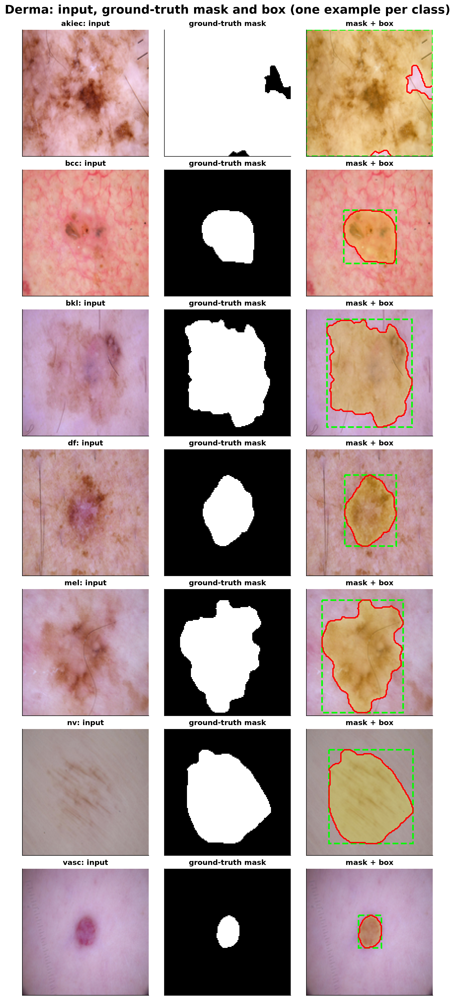

Saved derma_mask_statistics.png: 5434 x 1684 px at 300 dpi (+ PDF)


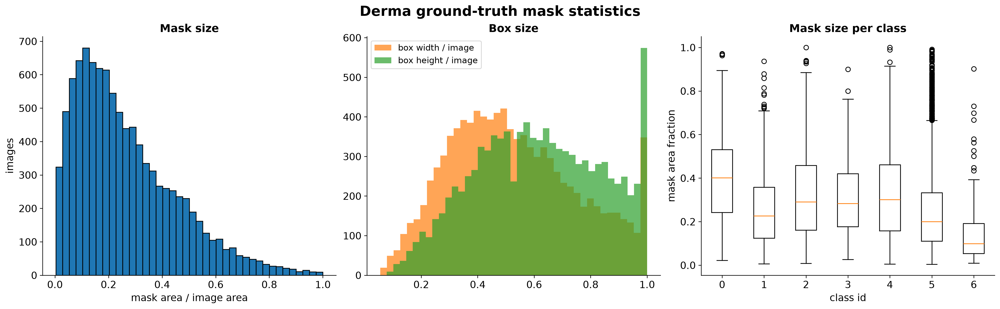

In [30]:
if DERMA is not None:
    qc_figure(DERMA, DERMA_SHORT, "derma_ground_truth_examples", "Derma: input, ground-truth mask and box (one example per class)")
    stats_figure(DERMA, "derma_mask_statistics", "Derma ground-truth mask statistics")
else:
    print("Derma QC skipped (dataset not available).")

In [31]:
BLOOD_CACHE = DATA_DIR / "blood" / f"blood_pbc_{IMG_SIZE}.npz"
BLOOD_CACHE.parent.mkdir(parents=True, exist_ok=True)
PSEUDO_CHANNEL = "green"          # "green" or "saturation"
PSEUDO_THRESHOLD_SHIFT = 0.0      # >0 enlarges the mask (higher threshold on the green channel), <0 shrinks it
PSEUDO_MIN_FRAC, PSEUDO_MAX_FRAC = 0.01, 0.85

In [32]:
def pseudo_cell_mask(rgb, channel=PSEUDO_CHANNEL, shift=PSEUDO_THRESHOLD_SHIFT, min_frac=PSEUDO_MIN_FRAC, max_frac=PSEUDO_MAX_FRAC):
    """Classical heuristic mask for the centred cell. Returns (bool mask, accepted: bool). PSEUDO-label, not ground truth."""
    h, w = rgb.shape[:2]
    if channel == "green":
        signal = -(filters.gaussian(rgb[..., 1].astype(np.float32) / 255.0, sigma=1.0))      # cells are DARKER in green -> invert
    else:
        signal = filters.gaussian(rgb2hsv(rgb)[..., 1].astype(np.float32), sigma=1.0)         # cells are MORE saturated
    if np.ptp(signal) < 0.05:
        return np.zeros((h, w), bool), False                                                  # (almost) flat image
    threshold = filters.threshold_otsu(signal) - shift
    foreground = signal > threshold
    foreground = ndi.binary_opening(foreground, structure=morphology.disk(1))
    labelled = measure.label(foreground, connectivity=2)
    best, best_score = None, -1.0
    cy, cx = (h - 1) / 2.0, (w - 1) / 2.0
    for region in measure.regionprops(labelled):
        if region.area < 0.003 * h * w:
            continue
        distance = math.hypot(region.centroid[0] - cy, region.centroid[1] - cx)
        score = region.area * math.exp(-(distance / (0.30 * h)) ** 2)
        if score > best_score:
            best, best_score = region.label, score
    if best is None:
        return np.zeros((h, w), bool), False
    mask = ndi.binary_fill_holes(labelled == best)
    frac = float(mask.mean())
    return mask, bool(min_frac <= frac <= max_frac)

In [33]:
def build_blood_dataset(force=False):
    if BLOOD_CACHE.exists() and not force:
        print("Using cached", BLOOD_CACHE); return
    from medmnist import BloodMNIST, INFO
    info = INFO["bloodmnist"]
    class_names = {int(k): str(v) for k, v in info["label"].items()}
    parts = {}
    try:
        for split in ("train", "val", "test"):
            dataset_obj = BloodMNIST(split=split, download=True, size=IMG_SIZE)
            parts[split] = (np.asarray(dataset_obj.imgs), np.asarray(dataset_obj.labels).reshape(-1).astype(int))
            assert len(parts[split][1]) == info["n_samples"][split], f"{split}: count differs from official metadata"
    except TypeError as exc:
        raise RuntimeError("BloodMNIST(size=...) needs medmnist>=3.0: run  %pip install -U \"medmnist>=3.0\"") from exc
    except Exception as exc:
        raise RuntimeError("BloodMNIST download/loading failed; check internet/disk space and delete a partial ~/.medmnist/bloodmnist_%d.npz if present. "
                           "Original error: %r" % (IMG_SIZE, exc)) from exc
    images = np.concatenate([parts[s][0] for s in ("train", "val", "test")]); labels = np.concatenate([parts[s][1] for s in ("train", "val", "test")])
    split = np.concatenate([[s] * len(parts[s][1]) for s in ("train", "val", "test")])
    assert images.shape[1:] == (IMG_SIZE, IMG_SIZE, 3) and images.dtype == np.uint8, f"unexpected image array {images.shape} {images.dtype}"
    n = len(labels)
    masks = np.zeros((n, IMG_SIZE, IMG_SIZE), np.uint8); has_mask = np.zeros(n, bool)
    t0 = time.perf_counter()
    for i in range(n):
        mask, ok = pseudo_cell_mask(images[i])
        masks[i], has_mask[i] = mask.astype(np.uint8), ok
        if (i + 1) % 2000 == 0:
            print(f"  pseudo-masks {i + 1}/{n} ({time.perf_counter() - t0:.0f}s)")
    masks[~has_mask] = 0                                     # rejected masks are cleared so they can never be used by accident
    boxes = boxes_from_masks(masks)
    sample_id = np.array([f"{s}_{i:05d}" for s, i in zip(split, np.concatenate([np.arange(len(parts[s][1])) for s in ("train", "val", "test")]))])
    meta = {"dataset": "BloodMNIST (official MedMNIST splits)", "image_size": IMG_SIZE, "class_names": {str(k): v for k, v in class_names.items()},
            "mask_source": f"PSEUDO: classical heuristic ({PSEUDO_CHANNEL} channel + Otsu, shift {PSEUDO_THRESHOLD_SHIFT}); NOT ground truth",
            "box_mode": BOX_MODE, "split": "official MedMNIST train/val/test", "note": "classes are cell types of healthy donors, not diseases"}
    save_seg_dataset(BLOOD_CACHE, images, labels, masks, boxes, has_mask, split, sample_id, sample_id, meta) 

In [34]:
BLOOD = None
try:
    build_blood_dataset()
    BLOOD = load_seg_dataset(BLOOD_CACHE)
    audit_seg_dataset(BLOOD, "blood")
    acceptance = pd.DataFrame({"class": [BLOOD["class_names"][int(c)] for c in BLOOD["labels"]], "accepted": BLOOD["has_mask"]}).groupby("class")["accepted"].agg(["mean", "size"])
    acceptance.columns = ["pseudo_mask_accepted_fraction", "n_images"]
    display(acceptance)
    acceptance.to_csv(RESULTS_DIR / "blood_pseudo_mask_acceptance_by_class.csv")
    print(f"Overall pseudo-mask acceptance: {BLOOD['has_mask'].mean():.1%}  (rejected images are excluded from segmentation/box training and scoring)")
    if EXPORT_PNG_FOLDERS:
        export_png_folders(BLOOD, "blood")
except Exception as exc:
    print("BLOOD DATASET NOT AVAILABLE:", exc)

Using cached C:\Users\sripo\OneDrive\Desktop\Hybrid_QIP\data\blood\blood_pbc_128.npz


,dataset,split,n_images,n_groups,classes_present,with_valid_mask,mask_area_frac_median
0,blood,train,11959,11959,8,11958,0.248474
1,blood,val,1712,1712,8,1712,0.240631
2,blood,test,3421,3421,8,3420,0.248444


,class_id,class_name,train,val,test
0,0,basophil,852,122,244
1,1,eosinophil,2181,312,624
2,2,erythroblast,1085,155,311
3,3,"immature granulocytes(myelocytes, metamyelocyt...",2026,290,579
4,4,lymphocyte,849,122,243
5,5,monocyte,993,143,284
6,6,neutrophil,2330,333,666
7,7,platelet,1643,235,470


blood: groups shared between splits (must be 0): 0


,pseudo_mask_accepted_fraction,n_images
class,,
basophil,1.000000,1218
eosinophil,1.000000,3117
erythroblast,1.000000,1551
"immature granulocytes(myelocytes, metamyelocytes and promyelocytes)",0.999655,2895
lymphocyte,1.000000,1214
monocyte,1.000000,1420
neutrophil,1.000000,3329
platelet,0.999574,2348


Overall pseudo-mask acceptance: 100.0%  (rejected images are excluded from segmentation/box training and scoring)


Saved blood_pseudo_label_examples.png: 3527 x 7234 px at 300 dpi (+ PDF)


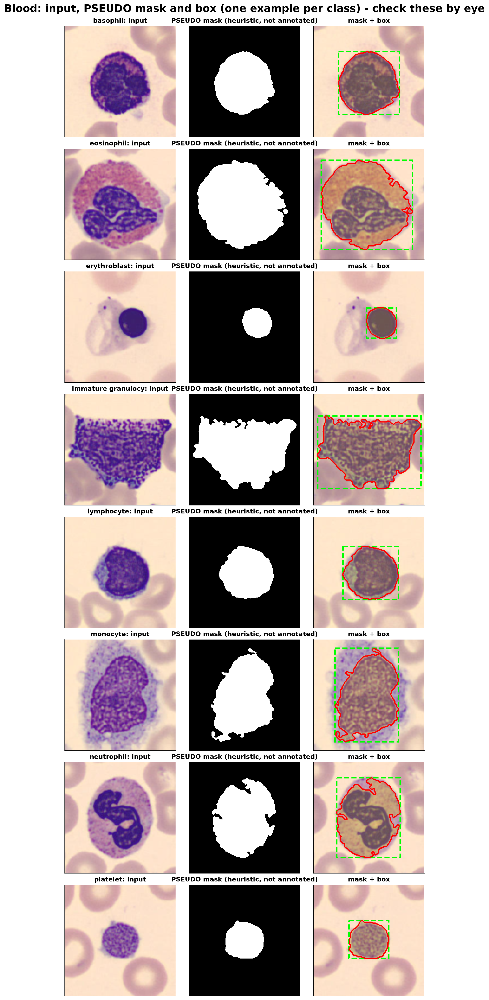

Saved blood_pseudo_mask_statistics.png: 5434 x 1684 px at 300 dpi (+ PDF)


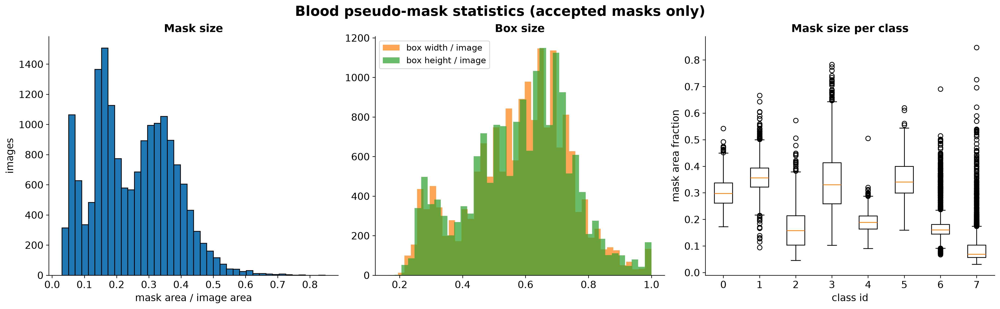

In [35]:
if BLOOD is not None:
    BLOOD_SHORT = {c: BLOOD["class_names"][c].split("(")[0].strip()[:18] for c in BLOOD["class_ids"]}
    qc_figure(BLOOD, BLOOD_SHORT, "blood_pseudo_label_examples", "Blood: input, PSEUDO mask and box (one example per class) - check these by eye",
              mask_label="PSEUDO mask (heuristic, not annotated)")
    stats_figure(BLOOD, "blood_pseudo_mask_statistics", "Blood pseudo-mask statistics (accepted masks only)")
else:
    print("Blood QC skipped (dataset not available).")

In [36]:
def blood_mask_agreement(n_sample=1500, seed=SEED):
    rows = []
    valid = np.flatnonzero(BLOOD["has_mask"])
    picks = np.random.default_rng(seed).choice(valid, size=min(n_sample, len(valid)), replace=False)
    for i in picks:
        m_g, ok_g = pseudo_cell_mask(BLOOD["images"][i], channel="green")
        m_s, ok_s = pseudo_cell_mask(BLOOD["images"][i], channel="saturation")
        rows.append({"class": BLOOD["class_names"][int(BLOOD["labels"][i])].split("(")[0].strip(), "ok_green": ok_g, "ok_saturation": ok_s,
                     "dice_green_vs_saturation": dice_iou(m_g, m_s)[0] if (ok_g and ok_s) else np.nan})
    return pd.DataFrame(rows)

if BLOOD is not None:
    agree = blood_mask_agreement()
    d = agree["dice_green_vs_saturation"].dropna()
    summary_q = {"n_checked": len(agree), "both_accepted": float((agree.ok_green & agree.ok_saturation).mean()),
                 "dice_median": float(d.median()), "dice_p10": float(d.quantile(0.10)), "dice_mean": float(d.mean())}
    display(pd.Series(summary_q).round(3).to_frame("value")); display(agree.groupby("class")["dice_green_vs_saturation"].agg(["median", "mean", "count"]).round(3))
    agree.to_csv(RESULTS_DIR / "blood_pseudo_mask_agreement.csv", index=False)
    BLOOD_MASKS_USABLE = summary_q["dice_median"] >= 0.90 and summary_q["dice_p10"] >= 0.75
    print("VERDICT:", "heuristics agree -> pseudo-masks are acceptable for ROI CROPPING; still report Blood segmentation only as 'agreement with a heuristic'."
          if BLOOD_MASKS_USABLE else
          "heuristics DISAGREE -> do NOT report Blood segmentation; use Blood for classification only and make every segmentation claim on ISIC (real masks).")
else:
    BLOOD_MASKS_USABLE = False; print("Blood not loaded.")

,value
n_checked,1500.000
both_accepted,0.999
dice_median,0.914
dice_p10,0.620
dice_mean,0.842


,median,mean,count
class,,,
basophil,0.975,0.958,103
eosinophil,0.932,0.868,300
erythroblast,0.711,0.728,141
immature granulocytes,0.837,0.826,247
lymphocyte,0.954,0.939,95
monocyte,0.904,0.882,125
neutrophil,0.965,0.914,278
platelet,0.757,0.677,209


VERDICT: heuristics DISAGREE -> do NOT report Blood segmentation; use Blood for classification only and make every segmentation claim on ISIC (real masks).


In [37]:
#Evaluation
def multiclass_metrics(y_true, y_pred, scores, class_ids):
    """Accuracy, balanced accuracy, macro/weighted metrics and one-vs-rest ROC-AUC (NaN where a class is absent)."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    scores = np.asarray(scores, dtype=np.float64)
    per_class_auc = {}
    for column, class_id in enumerate(class_ids):
        positive = (y_true == class_id)
        per_class_auc[class_id] = np.nan if (positive.sum() == 0 or positive.sum() == len(positive)) else float(roc_auc_score(positive, scores[:, column]))
    valid = [v for v in per_class_auc.values() if not np.isnan(v)]
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "macro_precision": float(precision_score(y_true, y_pred, labels=class_ids, average="macro", zero_division=0)),
        "macro_recall": float(recall_score(y_true, y_pred, labels=class_ids, average="macro", zero_division=0)),
        "macro_f1": float(f1_score(y_true, y_pred, labels=class_ids, average="macro", zero_division=0)),
        "weighted_f1": float(f1_score(y_true, y_pred, labels=class_ids, average="weighted", zero_division=0)),
        "roc_auc_ovr_macro": float(np.mean(valid)) if valid else np.nan,
    }, per_class_auc

In [38]:
def evaluate_predictions(cls_probs, seg_probs, labels, gt_masks, gt_boxes, has_mask, class_ids, threshold=0.5):
    """cls_probs (N,K) or None; seg_probs (N,H,W) in [0,1] or None. Returns (metrics dict, per-sample arrays)."""
    n = len(labels)
    out, per_sample = {}, {}
    if cls_probs is not None:
        predicted = np.asarray(class_ids)[np.argmax(cls_probs, axis=1)]
        out.update(multiclass_metrics(labels, predicted, cls_probs, class_ids)[0])
        per_sample["pred_label"] = predicted
        per_sample["correct"] = predicted == labels
    if seg_probs is not None:
        dice = np.full(n, np.nan); iou = np.full(n, np.nan); box_iou_values = np.full(n, np.nan)
        pred_boxes, pred_masks_ok = [None] * n, np.zeros(n, bool)
        for i in range(n):
            mask = postprocess_mask(seg_probs[i], threshold)
            pred_boxes[i] = mask_to_box(mask)
            pred_masks_ok[i] = mask.any()
            if has_mask[i]:
                dice[i], iou[i] = dice_iou(mask, gt_masks[i] > 0)
                gb = tuple(int(v) for v in gt_boxes[i]) if gt_boxes[i][0] >= 0 else None
                box_iou_values[i] = box_iou(pred_boxes[i], gb)
        valid = has_mask.astype(bool)
        out.update({"dice_mean": float(np.nanmean(dice)) if valid.any() else np.nan, "dice_std": float(np.nanstd(dice)) if valid.any() else np.nan,
                    "iou_mean": float(np.nanmean(iou)) if valid.any() else np.nan,
                    "box_iou_mean": float(np.nanmean(box_iou_values)) if valid.any() else np.nan,
                    "box_hit_iou50": float(np.mean(box_iou_values[valid] >= 0.5)) if valid.any() else np.nan,
                    "box_hit_iou75": float(np.mean(box_iou_values[valid] >= 0.75)) if valid.any() else np.nan,
                    "empty_prediction_rate": float(np.mean(~pred_masks_ok[valid])) if valid.any() else np.nan,
                    "n_scored_masks": int(valid.sum())})
        per_sample.update({"dice": dice, "iou": iou, "box_iou": box_iou_values, "pred_boxes": pred_boxes})
    if cls_probs is not None and seg_probs is not None and has_mask.any():
        joint = per_sample["correct"] & (per_sample["box_iou"] >= 0.5)
        out["joint_success"] = float(np.mean(joint[has_mask.astype(bool)]))        # right class AND box IoU >= 0.5
    return out, per_sample

In [39]:
def bootstrap_ci(per_sample, labels, class_ids, has_mask, n_boot=500, seed=0):
    """95% percentile bootstrap intervals over test images (resampling images, not training runs)."""
    rng = np.random.default_rng(seed)
    n = len(labels)
    stats = {k: [] for k in ("accuracy", "macro_f1", "dice_mean", "box_iou_mean", "joint_success")}
    valid = has_mask.astype(bool)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        for _ in range(n_boot):
            idx = rng.integers(0, n, n)
            if "pred_label" in per_sample:
                stats["accuracy"].append(np.mean(per_sample["pred_label"][idx] == labels[idx]))
                stats["macro_f1"].append(f1_score(labels[idx], per_sample["pred_label"][idx], labels=class_ids, average="macro", zero_division=0))
            if "dice" in per_sample:
                stats["dice_mean"].append(np.nanmean(per_sample["dice"][idx])); stats["box_iou_mean"].append(np.nanmean(per_sample["box_iou"][idx]))
            if "dice" in per_sample and "pred_label" in per_sample:
                ok = (per_sample["correct"] & (per_sample["box_iou"] >= 0.5))[idx]; v = valid[idx]
                stats["joint_success"].append(np.mean(ok[v]) if v.any() else np.nan)
    return {k: (float(np.nanpercentile(v, 2.5)), float(np.nanpercentile(v, 97.5))) for k, v in stats.items() if v}

In [40]:
_rng = np.random.default_rng(0)
_n, _k, _s = 40, 3, 32
_labels = _rng.integers(0, _k, _n)
_masks = np.zeros((_n, _s, _s), np.uint8)
for _i in range(_n):
    _y, _x = _rng.integers(4, 12, 2); _masks[_i, _y:_y + 12, _x:_x + 14] = 1
_boxes = boxes_from_masks(_masks); _has = np.ones(_n, bool)
_perfect_cls = np.eye(_k)[_labels]
_m, _ps = evaluate_predictions(_perfect_cls, _masks.astype(float), _labels, _masks, _boxes, _has, list(range(_k)))
assert _m["accuracy"] == 1.0 and abs(_m["dice_mean"] - 1.0) < 1e-12 and abs(_m["box_iou_mean"] - 1.0) < 1e-12 and _m["joint_success"] == 1.0, _m
_m0, _ = evaluate_predictions(_perfect_cls, np.zeros((_n, _s, _s)), _labels, _masks, _boxes, _has, list(range(_k)))
assert _m0["dice_mean"] == 0.0 and _m0["empty_prediction_rate"] == 1.0 and _m0["joint_success"] == 0.0, _m0
print("Evaluation unit tests passed (perfect and empty predictions behave as expected).")

Evaluation unit tests passed (perfect and empty predictions behave as expected).


count    17090.000
mean         0.252
std          0.124
min          0.031
1%           0.047
5%           0.061
50%          0.248
95%          0.451
99%          0.554
max          0.847
Saved blood_pseudo_mask_stress_check.png: 7780 x 3184 px at 300 dpi (+ PDF)


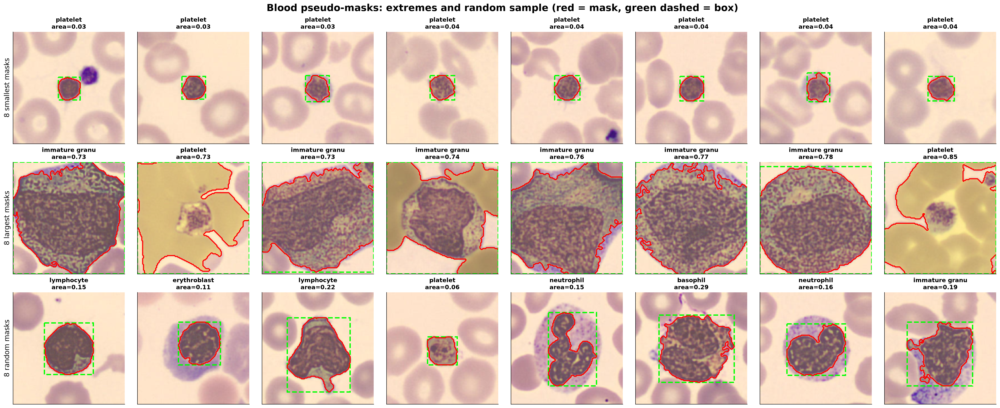

In [41]:
if BLOOD is not None:
    valid_ids = np.flatnonzero(BLOOD["has_mask"])
    areas = BLOOD["masks"][valid_ids].reshape(len(valid_ids), -1).mean(axis=1)
    print(pd.Series(areas).describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).round(3).to_string())
    order = np.argsort(areas)
    groups = {"8 smallest masks": valid_ids[order[:8]], "8 largest masks": valid_ids[order[-8:]],
              "8 random masks": np.random.default_rng(SEED).choice(valid_ids, 8, replace=False)}
    fig, axes = plt.subplots(3, 8, figsize=(26, 10.5), constrained_layout=True)
    for r, (name, ids_) in enumerate(groups.items()):
        for c, i in enumerate(ids_):
            draw_panel(axes[r, c], BLOOD["images"][i], mask=BLOOD["masks"][i], gt_box=tuple(int(v) for v in BLOOD["boxes"][i]),
                       title=f"{BLOOD['class_names'][int(BLOOD['labels'][i])].split('(')[0].strip()[:14]}\narea={BLOOD['masks'][i].mean():.2f}")
        axes[r, 0].set_ylabel(name, fontsize=13)
    fig.suptitle("Blood pseudo-masks: extremes and random sample (red = mask, green dashed = box)")
    save_fig(fig, "blood_pseudo_mask_stress_check"); plt.show()
else:
    print("Blood dataset not loaded - skip.")

In [42]:
#Choose the training subsets and class weights
def prepare_dataset(raw, name, cfg):
    """Index arrays per split (capped in smoke mode), class weights from the TRAINING split only."""
    idx = {}
    for k, split in enumerate(("train", "val", "test")):
        split_idx = np.flatnonzero(raw["split"] == split)
        cap = cfg[f"{split}_cap"]
        chosen = stratified_cap(raw["labels"][split_idx], cap, SEED + k)
        idx[split] = split_idx[chosen]
    counts = np.array([(raw["labels"][idx["train"]] == c).sum() for c in raw["class_ids"]], dtype=np.float64)
    weights = np.sqrt(counts.sum() / (len(counts) * np.maximum(counts, 1)))      # softened inverse-frequency weights
    weights = weights / weights.mean()
    return {"name": name, "raw": raw, "idx": idx, "class_ids": raw["class_ids"], "class_names": raw["class_names"], "class_weights": weights}

DATASETS = {}
if DERMA is not None:
    DATASETS["derma"] = prepare_dataset(DERMA, "derma", RUN_CONFIG)
if BLOOD is not None:
    DATASETS["blood"] = prepare_dataset(BLOOD, "blood", RUN_CONFIG)
for key, d in DATASETS.items():
    print(key, {s: len(i) for s, i in d["idx"].items()}, "| class weights:", np.round(d["class_weights"], 2))
if not DATASETS:
    raise RuntimeError("No dataset available. Provide HAM10000 files and/or fix the BloodMNIST download, then re-run the dataset cells.")

def get_split(d, split):
    raw, ids = d["raw"], d["idx"][split]
    return {k: raw[k][ids] for k in ("images", "labels", "masks", "boxes", "has_mask")}

derma {'train': 600, 'val': 200, 'test': 300} | class weights: [1.22 1.02 0.88 1.3  0.83 0.39 1.35]
blood {'train': 600, 'val': 200, 'test': 300} | class weights: [1.1  0.87 1.03 0.93 1.16 1.08 0.93 0.9 ]


In [43]:
baseline_rows = []
for key, d in DATASETS.items():
    train, test = get_split(d, "train"), get_split(d, "test")
    ids, n_test = d["class_ids"], len(test["labels"])
    majority = int(pd.Series(train["labels"]).mode()[0])
    probs = np.zeros((n_test, len(ids))); probs[:, ids.index(majority)] = 1.0
    full_image = np.ones((n_test, IMG_SIZE, IMG_SIZE), np.float32)
    valid_train = train["has_mask"].astype(bool)
    mean_box = np.rint(train["boxes"][valid_train].mean(axis=0)).astype(int)
    mean_box_masks = np.zeros((n_test, IMG_SIZE, IMG_SIZE), np.float32); mean_box_masks[:, mean_box[1]:mean_box[3], mean_box[0]:mean_box[2]] = 1
    for name, cls_p, seg_p in (("majority_class + whole-image mask/box", probs, full_image), ("majority_class + mean-training-box", probs, mean_box_masks)):
        metrics, _ = evaluate_predictions(cls_p, seg_p, test["labels"], test["masks"], test["boxes"], test["has_mask"], ids)
        baseline_rows.append({"dataset": key, "baseline": name, "n_test": n_test, **metrics})
    if key == "derma":        # Otsu on grayscale: classical lesion segmentation (lesions are darker than skin)
        gray = test["images"].mean(axis=3)
        def safe_otsu_mask(g):
            try:
                return (g < filters.threshold_otsu(g)).astype(np.float32)
            except ValueError:                                  # flat image: no threshold exists -> empty mask
                return np.zeros_like(g, dtype=np.float32)
        otsu_masks = np.stack([safe_otsu_mask(g) for g in gray])
        metrics, _ = evaluate_predictions(probs, otsu_masks, test["labels"], test["masks"], test["boxes"], test["has_mask"], ids)
        baseline_rows.append({"dataset": key, "baseline": "majority_class + Otsu(gray) mask", "n_test": n_test, **metrics})
    else:
        print("Blood: an Otsu baseline is not reported because the pseudo ground truth is itself produced by an Otsu-style heuristic.")
baseline_df = pd.DataFrame(baseline_rows)
display(baseline_df)
baseline_df.to_csv(RESULTS_DIR / "baselines.csv", index=False)

Blood: an Otsu baseline is not reported because the pseudo ground truth is itself produced by an Otsu-style heuristic.


,dataset,baseline,n_test,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,roc_auc_ovr_macro,dice_mean,dice_std,iou_mean,box_iou_mean,box_hit_iou50,box_hit_iou75,empty_prediction_rate,n_scored_masks,joint_success
0,derma,majority_class + whole-image mask/box,300,0.553333,0.142857,0.079048,0.142857,0.101778,0.394220,0.5,0.410399,0.224753,0.285975,0.391910,0.306667,0.123333,0.0,300,0.123333
1,derma,majority_class + mean-training-box,300,0.553333,0.142857,0.079048,0.142857,0.101778,0.394220,0.5,0.639440,0.183869,0.494359,0.516592,0.516667,0.103333,0.0,300,0.276667
2,derma,majority_class + Otsu(gray) mask,300,0.553333,0.142857,0.079048,0.142857,0.101778,0.394220,0.5,0.691526,0.298783,0.591784,0.671183,0.790000,0.553333,0.0,300,0.496667
3,blood,majority_class + whole-image mask/box,300,0.170000,0.125000,0.021250,0.125000,0.036325,0.049402,0.5,0.379764,0.155325,0.245971,0.354147,0.183333,0.013333,0.0,300,0.066667
4,blood,majority_class + mean-training-box,300,0.170000,0.125000,0.021250,0.125000,0.036325,0.049402,0.5,0.689441,0.184713,0.554102,0.628095,0.780000,0.273333,0.0,300,0.163333


In [44]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

In [45]:
FORCE_CPU = False
if FORCE_CPU:
    DEVICE = torch.device("cpu")
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif getattr(torch.backends, "mps", None) is not None and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")
BASE_CH, DEPTH, LR, WEIGHT_DECAY = 16, 4, 1e-3, 1e-4
assert IMG_SIZE % (2 ** DEPTH) == 0, f"IMG_SIZE must be divisible by {2 ** DEPTH}"
print("PyTorch", torch.__version__, "| device:", DEVICE)

PyTorch 2.13.0+cpu | device: cpu


In [46]:
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

In [47]:
class SegClsDataset(Dataset):
    def __init__(self, images, masks, labels, has_mask, augment=False, seed=0):
        self.images, self.masks, self.labels, self.has_mask = images, masks, labels, has_mask
        self.augment, self.rng = augment, np.random.default_rng(seed)
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        image, mask = self.images[i], self.masks[i]
        gain, bias = 1.0, 0.0
        if self.augment:
            if self.rng.random() < 0.5:
                image, mask = image[:, ::-1], mask[:, ::-1]
            if self.rng.random() < 0.5:
                image, mask = image[::-1], mask[::-1]
            k = int(self.rng.integers(0, 4))
            image, mask = np.rot90(image, k), np.rot90(mask, k)
            gain, bias = self.rng.uniform(0.9, 1.1), self.rng.uniform(-0.05, 0.05)
        x = torch.from_numpy(np.ascontiguousarray(image)).permute(2, 0, 1).float() / 255.0
        x = (x * gain + bias).clamp(0.0, 1.0)
        m = torch.from_numpy(np.ascontiguousarray(mask)).float().unsqueeze(0)
        return x, m, int(self.labels[i]), float(self.has_mask[i])

In [48]:
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False), nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False), nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True))
    def forward(self, x):
        return self.block(x)

In [49]:
class MultiTaskUNet(nn.Module):
    """forward(x) -> (class_logits or None, mask_logits or None). x: (B,3,H,W) in [0,1]; mask_logits: (B,1,H,W)."""
    def __init__(self, n_classes, base=BASE_CH, depth=DEPTH, use_decoder=True, use_cls=True, dropout=0.2):
        super().__init__()
        widths = [base * 2 ** i for i in range(depth + 1)]                     # e.g. [16, 32, 64, 128, 256]
        self.depth, self.use_decoder, self.use_cls = depth, use_decoder, use_cls
        self.encoders = nn.ModuleList([ConvBlock(3 if i == 0 else widths[i - 1], widths[i]) for i in range(depth + 1)])
        self.pool = nn.MaxPool2d(2)
        if use_cls:
            self.cls_head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(dropout), nn.Linear(widths[-1], n_classes))
        if use_decoder:
            # ups[j]: level depth-j -> depth-j-1 ; decoders[j] consumes concat(upsampled, skip of level depth-j-1)
            self.ups = nn.ModuleList([nn.ConvTranspose2d(widths[depth - j], widths[depth - j - 1], 2, stride=2) for j in range(depth)])
            self.decoders = nn.ModuleList([ConvBlock(2 * widths[depth - j - 1], widths[depth - j - 1]) for j in range(depth)])
            self.seg_head = nn.Conv2d(widths[0], 1, 1)
    def forward(self, x):
        skips = []
        for level, encoder in enumerate(self.encoders):
            x = encoder(x)
            if level < self.depth:
                skips.append(x)
                x = self.pool(x)
        class_logits = self.cls_head(x) if self.use_cls else None
        mask_logits = None
        if self.use_decoder:
            for up, decoder, skip in zip(self.ups, self.decoders, reversed(skips)):
                x = decoder(torch.cat([up(x), skip], dim=1))
            mask_logits = self.seg_head(x)
        return class_logits, mask_logits

In [50]:
def seg_loss_fn(mask_logits, masks, valid):
    """BCE + soft Dice per image, averaged over images that HAVE a valid mask (valid: (B,) float 0/1)."""
    bce = F.binary_cross_entropy_with_logits(mask_logits, masks, reduction="none").mean(dim=(1, 2, 3))
    prob = torch.sigmoid(mask_logits)
    inter = (prob * masks).sum(dim=(1, 2, 3)); denom = prob.sum(dim=(1, 2, 3)) + masks.sum(dim=(1, 2, 3))
    dice = (2.0 * inter + 1.0) / (denom + 1.0)
    return ((bce + (1.0 - dice)) * valid).sum() / valid.sum().clamp_min(1.0)


In [51]:
@torch.no_grad()
def predict_arrays(model, images, batch=64):
    """images (N,H,W,3) uint8 -> (class probabilities (N,K) or None, mask probabilities (N,H,W) or None)."""
    model.eval()
    cls_out, seg_out = [], []
    for start in range(0, len(images), batch):
        x = torch.from_numpy(np.ascontiguousarray(images[start:start + batch])).permute(0, 3, 1, 2).float().div(255.0).to(DEVICE)
        class_logits, mask_logits = model(x)
        if class_logits is not None:
            cls_out.append(torch.softmax(class_logits, dim=1).cpu().numpy())
        if mask_logits is not None:
            seg_out.append(torch.sigmoid(mask_logits)[:, 0].cpu().numpy())
    return (np.concatenate(cls_out) if cls_out else None), (np.concatenate(seg_out) if seg_out else None)

EXPERIMENTS = {
    "multitask": dict(use_cls=True, use_decoder=True, w_cls=1.0, w_seg=1.0),
    "cls_only":  dict(use_cls=True, use_decoder=False, w_cls=1.0, w_seg=0.0),
    "seg_only":  dict(use_cls=False, use_decoder=True, w_cls=0.0, w_seg=1.0),
}

In [52]:
def selection_score(metrics, exp_cfg):
    parts = []
    if exp_cfg["use_cls"]: parts.append(metrics["macro_f1"])
    if exp_cfg["use_decoder"]: parts.append(metrics["dice_mean"])
    return float(np.mean(parts))

In [53]:
#training function
def train_one_run(d, exp_name, seed, run_cfg):
    exp_cfg = EXPERIMENTS[exp_name]
    set_seed(seed)
    tr, va, te = get_split(d, "train"), get_split(d, "val"), get_split(d, "test")
    ids = d["class_ids"]
    model = MultiTaskUNet(len(ids), use_decoder=exp_cfg["use_decoder"], use_cls=exp_cfg["use_cls"]).to(DEVICE)
    n_params = sum(p.numel() for p in model.parameters())
    class_w = torch.tensor(d["class_weights"], dtype=torch.float32, device=DEVICE)
    loader = DataLoader(SegClsDataset(tr["images"], tr["masks"], tr["labels"], tr["has_mask"], augment=True, seed=seed),
                        batch_size=run_cfg["batch"], shuffle=True)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=2)
    history, best_score, best_state, best_epoch, bad_epochs = [], -np.inf, None, 0, 0
    t_start = time.perf_counter()
    for epoch in range(1, run_cfg["epochs"] + 1):
        model.train(); t_epoch = time.perf_counter(); running, seen = 0.0, 0
        for x, m, y, valid in loader:
            x, m, y, valid = x.to(DEVICE), m.to(DEVICE), y.to(DEVICE), valid.float().to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            class_logits, mask_logits = model(x)
            loss = 0.0
            if exp_cfg["use_cls"]:
                loss = loss + exp_cfg["w_cls"] * F.cross_entropy(class_logits, y, weight=class_w)
            if exp_cfg["use_decoder"]:
                loss = loss + exp_cfg["w_seg"] * seg_loss_fn(mask_logits, m, valid)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            optimizer.step()
            running += float(loss.item()) * len(y); seen += len(y)
        cls_p, seg_p = predict_arrays(model, va["images"])
        val_metrics, _ = evaluate_predictions(cls_p, seg_p, va["labels"], va["masks"], va["boxes"], va["has_mask"], ids)
        score = selection_score(val_metrics, exp_cfg)
        if not np.isfinite(score):                               # e.g. no valid masks in the validation subset
            score = -1.0
        scheduler.step(score)
        history.append({"epoch": epoch, "train_loss": running / max(seen, 1), "val_score": score, "lr": optimizer.param_groups[0]["lr"],
                        "epoch_seconds": time.perf_counter() - t_epoch, **{f"val_{k}": v for k, v in val_metrics.items() if k in ("macro_f1", "balanced_accuracy", "dice_mean", "box_iou_mean")}})
        print(f"[{d['name']}/{exp_name}/seed{seed}] epoch {epoch}/{run_cfg['epochs']} loss={history[-1]['train_loss']:.4f} "
              f"val_score={score:.4f} ({history[-1]['epoch_seconds']:.0f}s)")
        if score > best_score + 1e-4:
            best_score, best_epoch, bad_epochs = score, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad_epochs += 1
            if bad_epochs >= run_cfg["patience"]:
                print("  early stopping"); break
    train_seconds = time.perf_counter() - t_start
    if best_state is None:
        best_state = copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    t0 = time.perf_counter()
    cls_p, seg_p = predict_arrays(model, te["images"])
    infer_ms = (time.perf_counter() - t0) / len(te["labels"]) * 1000.0          # network forward only (no post-processing)
    metrics, per_sample = evaluate_predictions(cls_p, seg_p, te["labels"], te["masks"], te["boxes"], te["has_mask"], ids)
    ci = bootstrap_ci(per_sample, te["labels"], ids, te["has_mask"], n_boot=500, seed=seed)
    ckpt = MODEL_DIR / f"{d['name']}_{exp_name}_seed{seed}.pt"
    torch.save({"state_dict": model.state_dict(), "n_classes": len(ids), "use_decoder": exp_cfg["use_decoder"], "use_cls": exp_cfg["use_cls"],
                "img_size": IMG_SIZE, "class_names": d["class_names"], "base": BASE_CH, "depth": DEPTH}, ckpt)
    row = {"dataset": d["name"], "experiment": exp_name, "seed": seed, "n_train": len(tr["labels"]), "n_val": len(va["labels"]), "n_test": len(te["labels"]),
           "epochs_run": len(history), "best_epoch": best_epoch, "train_seconds": train_seconds, "inference_ms_per_image": infer_ms,
           "n_parameters": n_params, "device": str(DEVICE), "run_mode": RUN_MODE, **metrics,
           **{f"{k}_ci95": f"[{lo:.3f}, {hi:.3f}]" for k, (lo, hi) in ci.items()}}
    return row, pd.DataFrame(history), {"cls_probs": cls_p, "seg_probs": seg_p, "per_sample": per_sample, "checkpoint": str(ckpt)}

In [54]:
set_seed(0)
probe = MultiTaskUNet(n_classes=7).to(DEVICE)
x_probe = torch.rand(4, 3, IMG_SIZE, IMG_SIZE, device=DEVICE)
c_out, s_out = probe(x_probe)
assert c_out.shape == (4, 7), c_out.shape
assert s_out.shape == (4, 1, IMG_SIZE, IMG_SIZE), s_out.shape
for use_cls, use_dec in ((True, False), (False, True)):
    c_o, s_o = MultiTaskUNet(5, use_decoder=use_dec, use_cls=use_cls).to(DEVICE)(x_probe)
    assert (c_o is not None) == use_cls and (s_o is not None) == use_dec
print("Output shapes OK. Parameters (multi-task):", sum(p.numel() for p in probe.parameters()))

Output shapes OK. Parameters (multi-task): 1944376


In [55]:
first = next(iter(DATASETS.values()))
tiny = get_split({**first, "idx": {"train": first["idx"]["train"][:16], "val": first["idx"]["val"][:4], "test": first["idx"]["test"][:4]}}, "train")
tiny_loader = DataLoader(SegClsDataset(tiny["images"], tiny["masks"], tiny["labels"], tiny["has_mask"], augment=False), batch_size=16)
xb, mb, yb, vb = next(iter(tiny_loader))
xb, mb, yb, vb = xb.to(DEVICE), mb.to(DEVICE), yb.to(DEVICE), vb.float().to(DEVICE)
model_t = MultiTaskUNet(len(first["class_ids"])).to(DEVICE)
opt_t = torch.optim.AdamW(model_t.parameters(), lr=LR)
losses = []
for step in range(40):
    opt_t.zero_grad()
    c_l, s_l = model_t(xb)
    loss_t = F.cross_entropy(c_l, yb) + seg_loss_fn(s_l, mb, vb)
    loss_t.backward(); opt_t.step(); losses.append(float(loss_t.item()))
print(f"Tiny-batch overfit: loss {losses[0]:.3f} -> {losses[-1]:.3f}")
if not losses[-1] < 0.8 * losses[0]:
    warnings.warn("Loss did not fall by 20% in 40 steps on 16 images - inspect data/model before long runs.")
else:
    print("Optimisation sanity check passed.")
del probe, model_t

Tiny-batch overfit: loss 3.401 -> 0.761
Optimisation sanity check passed.


In [56]:
RUN_EXPERIMENTS = ["multitask", "cls_only", "seg_only"]     # remove entries to run fewer; skipped ones are listed as not_run below
run_rows, histories, RUN_STORE = [], {}, {}
runs_csv = RESULTS_DIR / "experiment_runs.csv"
for key, d in DATASETS.items():
    for exp_name in RUN_EXPERIMENTS:
        for seed in RUN_CONFIG["seeds"]:
            try:
                row, history, store = train_one_run(d, exp_name, seed, RUN_CONFIG)
            except Exception as exc:
                import traceback; traceback.print_exc()
                row = {"dataset": key, "experiment": exp_name, "seed": seed, "status": f"failed: {type(exc).__name__}: {exc}", "run_mode": RUN_MODE}
                history, store = None, None
            else:
                row["status"] = "completed"
                history.to_csv(RESULTS_DIR / f"history_{key}_{exp_name}_seed{seed}.csv", index=False)
                histories[(key, exp_name, seed)] = history
                if seed == RUN_CONFIG["seeds"][0]:
                    RUN_STORE[(key, exp_name)] = store              # keep predictions of the first seed only (memory)
            run_rows.append(row)
            pd.DataFrame(run_rows).to_csv(runs_csv, index=False)
runs_df = pd.DataFrame(run_rows)
for key in ("derma", "blood"):
    if key not in DATASETS:
        print(f"NOT RUN: {key} (dataset unavailable)")
display(runs_df)

[derma/multitask/seed42] epoch 1/3 loss=2.9067 val_score=0.2852 (32s)
[derma/multitask/seed42] epoch 2/3 loss=2.5888 val_score=0.2707 (31s)
[derma/multitask/seed42] epoch 3/3 loss=2.4291 val_score=0.4498 (32s)
[derma/cls_only/seed42] epoch 1/3 loss=1.6647 val_score=0.1066 (12s)
[derma/cls_only/seed42] epoch 2/3 loss=1.5337 val_score=0.2102 (11s)
[derma/cls_only/seed42] epoch 3/3 loss=1.4447 val_score=0.3542 (11s)
[derma/seg_only/seed42] epoch 1/3 loss=1.0721 val_score=0.6397 (28s)
[derma/seg_only/seed42] epoch 2/3 loss=0.8775 val_score=0.7291 (29s)
[derma/seg_only/seed42] epoch 3/3 loss=0.7782 val_score=0.7858 (31s)
[blood/multitask/seed42] epoch 1/3 loss=2.2200 val_score=0.2476 (36s)
[blood/multitask/seed42] epoch 2/3 loss=1.5300 val_score=0.3938 (30s)
[blood/multitask/seed42] epoch 3/3 loss=1.3216 val_score=0.7519 (30s)
[blood/cls_only/seed42] epoch 1/3 loss=1.1189 val_score=0.0297 (11s)
[blood/cls_only/seed42] epoch 2/3 loss=0.7484 val_score=0.1032 (10s)
[blood/cls_only/seed42] epoc

,dataset,experiment,seed,n_train,n_val,n_test,epochs_run,best_epoch,train_seconds,inference_ms_per_image,...,box_hit_iou75,empty_prediction_rate,n_scored_masks,joint_success,accuracy_ci95,macro_f1_ci95,dice_mean_ci95,box_iou_mean_ci95,joint_success_ci95,status
0,derma,multitask,42,600,200,300,3,3,94.778757,10.821299,...,0.446667,0.0,300.0,0.366667,"[0.407, 0.515]","[0.219, 0.315]","[0.712, 0.759]","[0.623, 0.677]","[0.317, 0.422]",completed
1,derma,cls_only,42,600,200,300,3,3,33.496440,3.684826,...,NaN,NaN,NaN,NaN,"[0.482, 0.595]","[0.238, 0.346]",NaN,NaN,NaN,completed
2,derma,seg_only,42,600,200,300,3,3,87.756333,12.700752,...,0.656667,0.0,300.0,NaN,NaN,NaN,"[0.788, 0.829]","[0.706, 0.756]",NaN,completed
3,blood,multitask,42,600,200,300,3,3,95.386996,10.655462,...,0.863333,0.0,300.0,0.600000,"[0.580, 0.683]","[0.536, 0.626]","[0.911, 0.937]","[0.871, 0.907]","[0.545, 0.655]",completed
4,blood,cls_only,42,600,200,300,3,3,31.179428,3.762547,...,NaN,NaN,NaN,NaN,"[0.620, 0.727]","[0.531, 0.637]",NaN,NaN,NaN,completed
5,blood,seg_only,42,600,200,300,3,3,85.962925,10.260084,...,0.770000,0.0,300.0,NaN,NaN,NaN,"[0.846, 0.887]","[0.798, 0.852]",NaN,completed


,dataset,experiment,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,macro_f1_mean,macro_f1_std,weighted_f1_mean,weighted_f1_std,...,box_hit_iou50_std,box_hit_iou75_mean,box_hit_iou75_std,joint_success_mean,joint_success_std,inference_ms_per_image_mean,inference_ms_per_image_std,train_seconds_mean,train_seconds_std,n_seeds
0,blood,cls_only,0.676667,NaN,0.634265,NaN,0.588504,NaN,0.640574,NaN,...,NaN,NaN,NaN,NaN,NaN,3.762547,NaN,31.179428,NaN,1
1,blood,multitask,0.633333,NaN,0.603040,NaN,0.584484,NaN,0.625664,NaN,...,NaN,0.863333,NaN,0.600000,NaN,10.655462,NaN,95.386996,NaN,1
2,blood,seg_only,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,0.770000,NaN,NaN,NaN,10.260084,NaN,85.962925,NaN,1
3,derma,cls_only,0.540000,NaN,0.318492,NaN,0.295694,NaN,0.507895,NaN,...,NaN,NaN,NaN,NaN,NaN,3.684826,NaN,33.496440,NaN,1
4,derma,multitask,0.460000,NaN,0.344398,NaN,0.267109,NaN,0.491603,NaN,...,NaN,0.446667,NaN,0.366667,NaN,10.821299,NaN,94.778757,NaN,1
5,derma,seg_only,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,0.656667,NaN,NaN,NaN,12.700752,NaN,87.756333,NaN,1


SMOKE MODE: these numbers come from tiny subsets and a few epochs; they only show that the pipeline runs.
Saved derma_learning_curves.png: 4534 x 1684 px at 300 dpi (+ PDF)


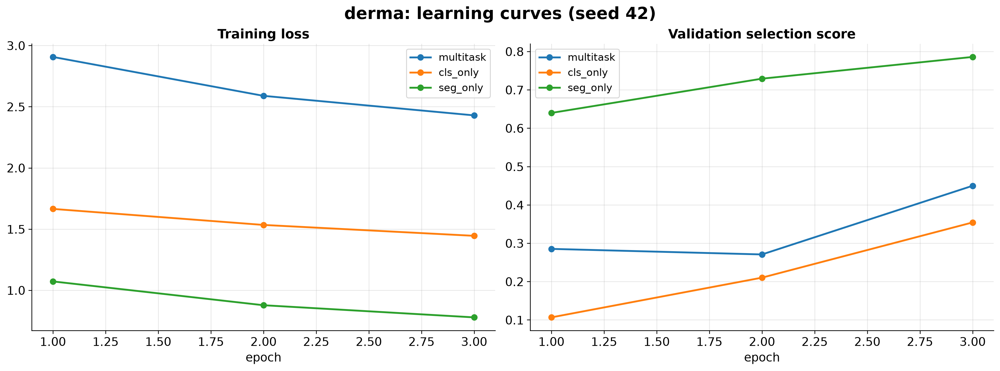

Saved blood_learning_curves.png: 4534 x 1684 px at 300 dpi (+ PDF)


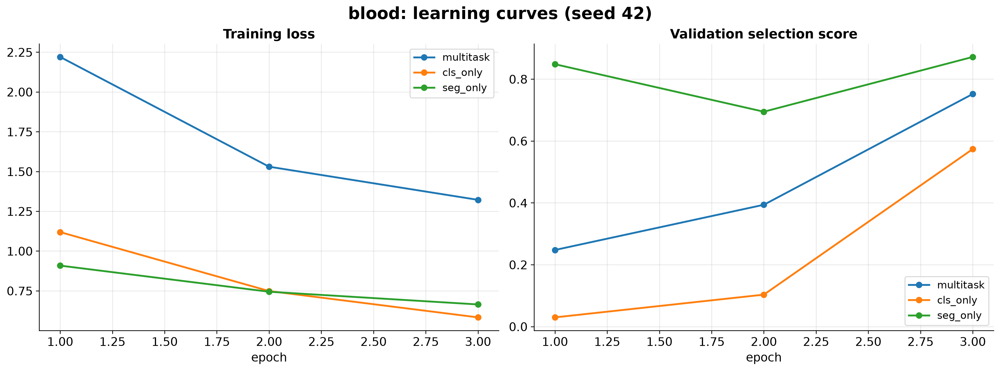

Saved derma_multitask_confusion.png: 3128 x 2734 px at 300 dpi (+ PDF)


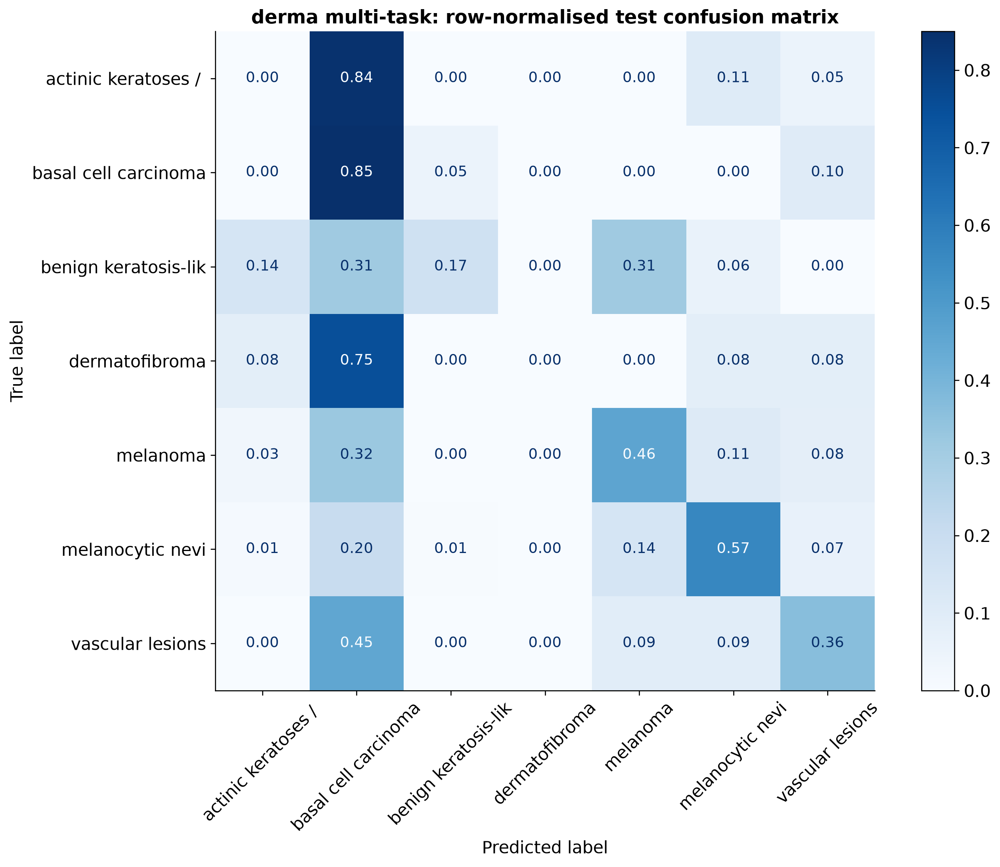

,precision,recall,f1-score,support
actinic keratoses /,0.000000,0.000000,0.000000,19.00
basal cell carcinoma,0.163462,0.850000,0.274194,20.00
benign keratosis-lik,0.750000,0.171429,0.279070,35.00
dermatofibroma,0.000000,0.000000,0.000000,12.00
melanoma,0.320755,0.459459,0.377778,37.00
melanocytic nevi,0.903846,0.566265,0.696296,166.00
vascular lesions,0.181818,0.363636,0.242424,11.00
accuracy,0.460000,0.460000,0.460000,0.46
macro avg,0.331412,0.344398,0.267109,300.00
weighted avg,0.644752,0.460000,0.491603,300.00


Saved derma_multitask_dice_boxiou.png: 4534 x 1684 px at 300 dpi (+ PDF)


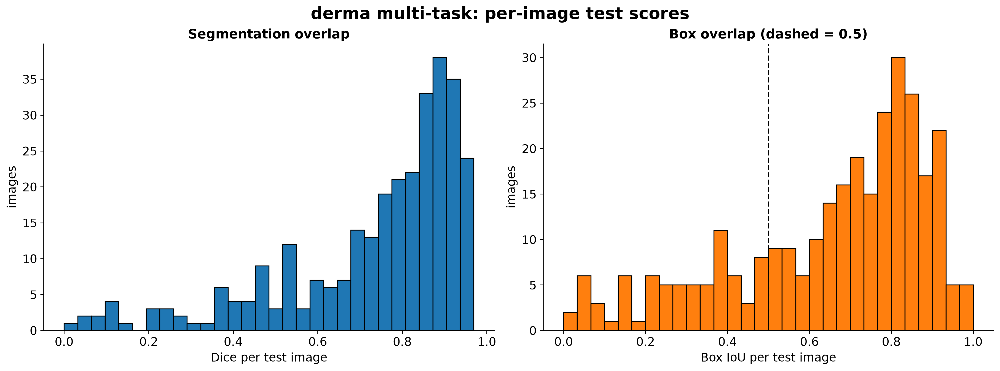

Saved blood_multitask_confusion.png: 3126 x 2734 px at 300 dpi (+ PDF)


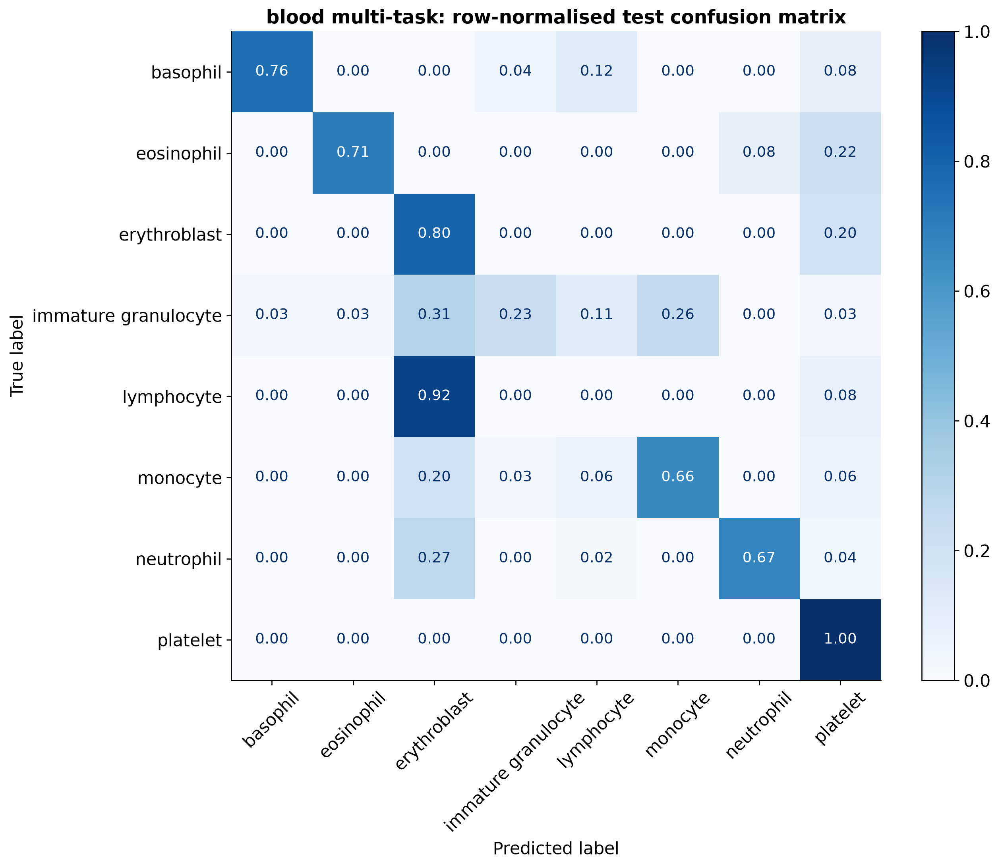

,precision,recall,f1-score,support
basophil,0.950000,0.760000,0.844444,25.000000
eosinophil,0.972973,0.705882,0.818182,51.000000
erythroblast,0.296296,0.800000,0.432432,30.000000
immature granulocyte,0.800000,0.228571,0.355556,35.000000
lymphocyte,0.000000,0.000000,0.000000,26.000000
monocyte,0.718750,0.657143,0.686567,35.000000
neutrophil,0.902439,0.672727,0.770833,55.000000
platelet,0.623188,1.000000,0.767857,43.000000
accuracy,0.633333,0.633333,0.633333,0.633333
macro avg,0.657956,0.603040,0.584484,300.000000


Saved blood_multitask_dice_boxiou.png: 4534 x 1684 px at 300 dpi (+ PDF)


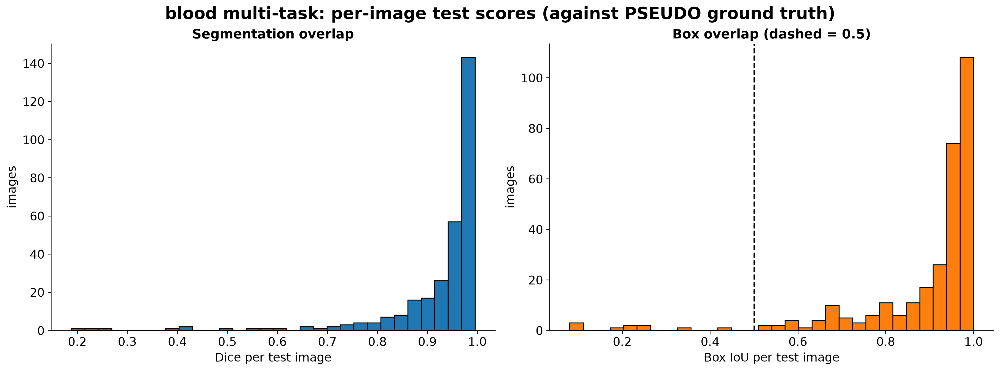

In [57]:
completed = runs_df[runs_df["status"] == "completed"].copy()
metric_cols = [c for c in ["accuracy", "balanced_accuracy", "macro_f1", "weighted_f1", "roc_auc_ovr_macro", "dice_mean", "iou_mean",
                           "box_iou_mean", "box_hit_iou50", "box_hit_iou75", "joint_success", "inference_ms_per_image", "train_seconds"] if c in completed.columns]
summary = completed.groupby(["dataset", "experiment"])[metric_cols].agg(["mean", "std"])
summary.columns = [f"{a}_{b}" for a, b in summary.columns]
summary = summary.reset_index()
summary["n_seeds"] = completed.groupby(["dataset", "experiment"]).size().values
display(summary)
summary.to_csv(RESULTS_DIR / "results_summary_by_experiment.csv", index=False)
if RUN_MODE == "smoke":
    print("SMOKE MODE: these numbers come from tiny subsets and a few epochs; they only show that the pipeline runs.")

# ---- learning curves (first seed)
for key in DATASETS:
    keys = [k for k in histories if k[0] == key and k[2] == RUN_CONFIG["seeds"][0]]
    if not keys:
        continue
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), constrained_layout=True)
    for (_, exp_name, _) in keys:
        h = histories[(key, exp_name, RUN_CONFIG["seeds"][0])]
        axes[0].plot(h["epoch"], h["train_loss"], marker="o", linewidth=2, label=exp_name); axes[1].plot(h["epoch"], h["val_score"], marker="o", linewidth=2, label=exp_name)
    axes[0].set_title("Training loss"); axes[1].set_title("Validation selection score")
    for a in axes:
        a.set_xlabel("epoch"); a.grid(alpha=0.3); a.legend()
    fig.suptitle(f"{key}: learning curves (seed {RUN_CONFIG['seeds'][0]})"); save_fig(fig, f"{key}_learning_curves"); plt.show()

# ---- confusion matrices, per-class report, Dice / box-IoU histograms for the multi-task model (first seed)
for key, d in DATASETS.items():
    if (key, "multitask") not in RUN_STORE:
        continue
    store = RUN_STORE[(key, "multitask")]; te = get_split(d, "test"); ids = d["class_ids"]
    names = [d["class_names"][c].split("(")[0].strip()[:20] for c in ids]
    fig, ax = plt.subplots(figsize=(10.5, 9), constrained_layout=True)
    ConfusionMatrixDisplay.from_predictions(te["labels"], store["per_sample"]["pred_label"], labels=ids, display_labels=names, normalize="true",
                                            values_format=".2f", cmap="Blues", ax=ax, xticks_rotation=45, text_kw={"fontsize": 11})
    ax.set_title(f"{key} multi-task: row-normalised test confusion matrix"); ax.grid(False)
    save_fig(fig, f"{key}_multitask_confusion"); plt.show()
    report = pd.DataFrame(classification_report(te["labels"], store["per_sample"]["pred_label"], labels=ids, target_names=names, output_dict=True, zero_division=0)).T
    display(report); report.to_csv(RESULTS_DIR / f"{key}_multitask_per_class_report.csv")
    valid = te["has_mask"].astype(bool)
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), constrained_layout=True)
    axes[0].hist(store["per_sample"]["dice"][valid], bins=30, color="tab:blue", edgecolor="black"); axes[0].set_xlabel("Dice per test image"); axes[0].set_title("Segmentation overlap")
    axes[1].hist(store["per_sample"]["box_iou"][valid], bins=30, color="tab:orange", edgecolor="black"); axes[1].axvline(0.5, color="k", linestyle="--"); axes[1].set_xlabel("Box IoU per test image"); axes[1].set_title("Box overlap (dashed = 0.5)")
    for a in axes: a.set_ylabel("images")
    fig.suptitle(f"{key} multi-task: per-image test scores" + (" (against PSEUDO ground truth)" if key == "blood" else "")); save_fig(fig, f"{key}_multitask_dice_boxiou"); plt.show()

Saved derma_predictions_random.png: 5275 x 2854 px at 300 dpi (+ PDF)


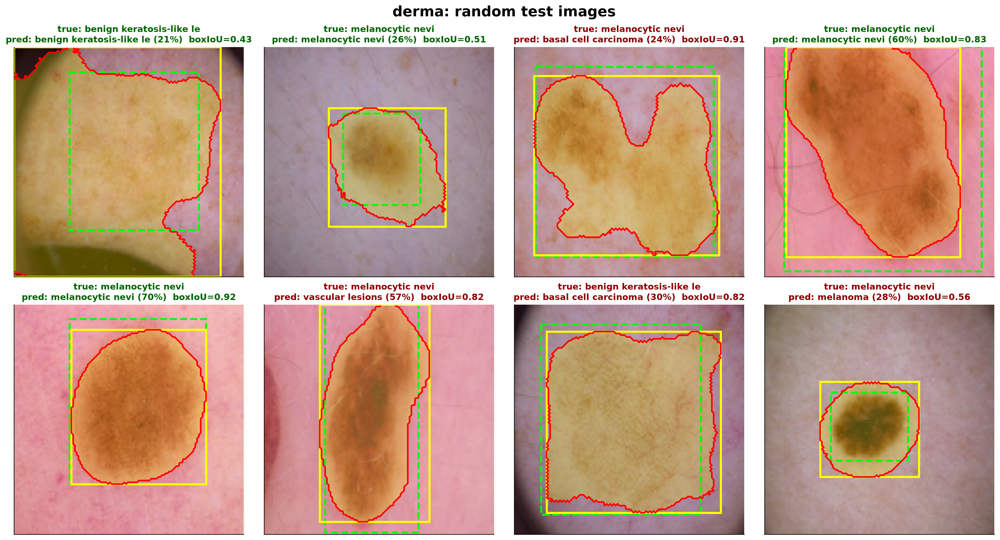

Saved derma_predictions_worst_boxes.png: 5304 x 2854 px at 300 dpi (+ PDF)


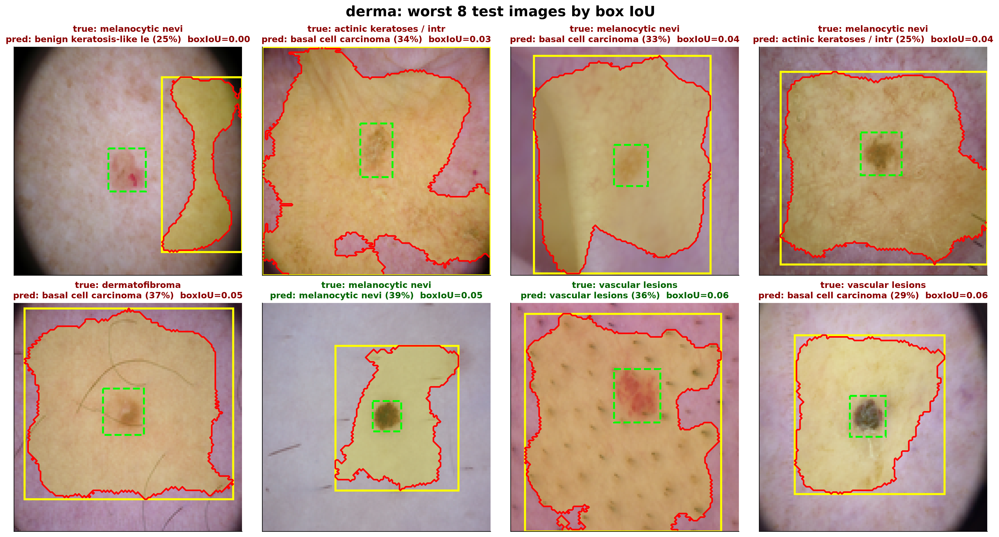

Saved blood_predictions_random.png: 5234 x 2854 px at 300 dpi (+ PDF)


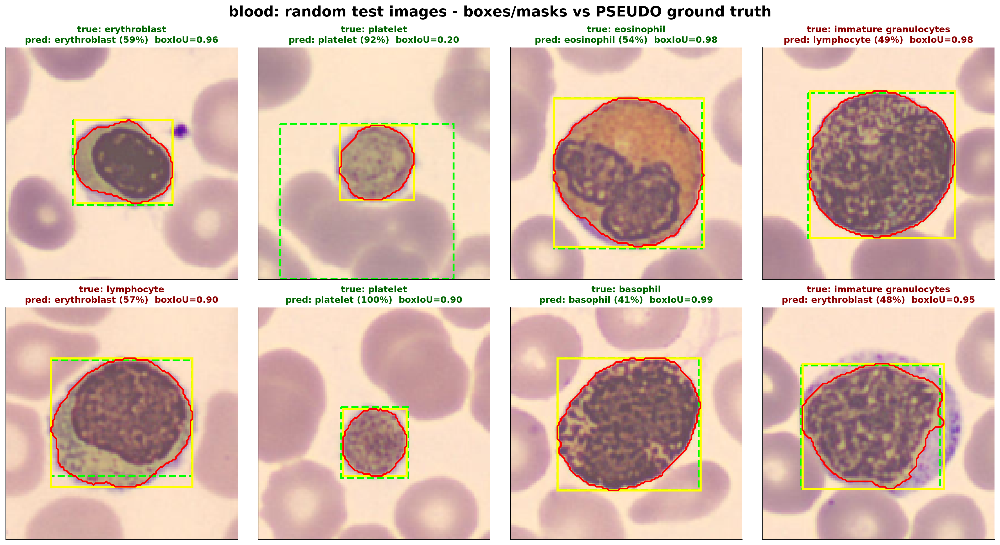

Saved blood_predictions_worst_boxes.png: 5234 x 2854 px at 300 dpi (+ PDF)


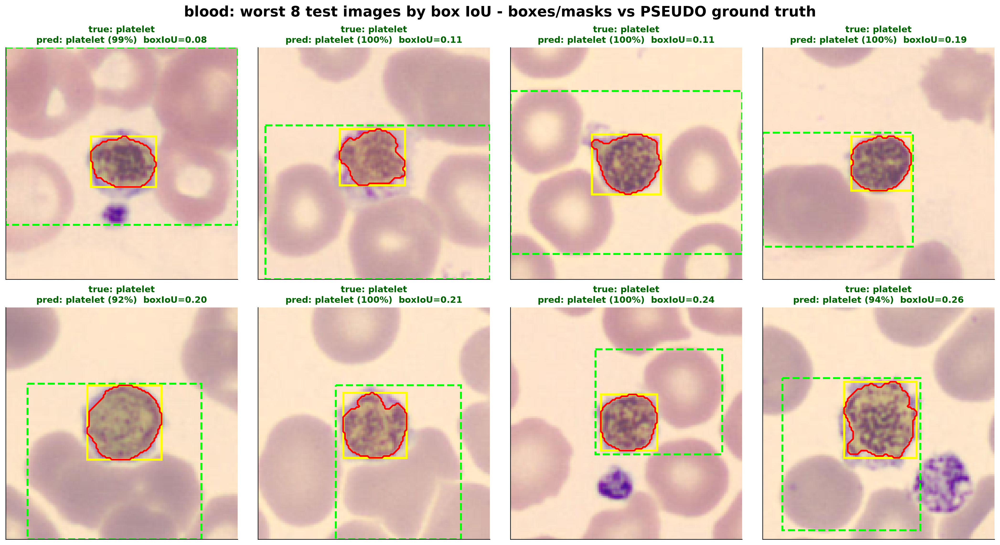

In [58]:
def prediction_grid(d, store, fname, title, which="random", n=8, seed=SEED):
    te = get_split(d, "test"); ps = store["per_sample"]; ids = d["class_ids"]
    valid = np.flatnonzero(te["has_mask"].astype(bool))
    if which == "random":
        picks = np.random.default_rng(seed).choice(valid, size=min(n, len(valid)), replace=False)
    else:
        picks = valid[np.argsort(ps["box_iou"][valid])[:n]]                     # worst box IoU first
    cols = 4; rows = int(math.ceil(len(picks) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4.4 * cols, 4.7 * rows), constrained_layout=True, squeeze=False)
    for ax, i in zip(axes.ravel(), picks):
        pred_mask = postprocess_mask(store["seg_probs"][i])
        probs = store["cls_probs"][i]; top = int(np.argmax(probs))
        gt_name = d["class_names"][int(te["labels"][i])].split("(")[0].strip()[:24]; pr_name = d["class_names"][ids[top]].split("(")[0].strip()[:24]
        colour = "darkgreen" if ids[top] == te["labels"][i] else "darkred"
        draw_panel(ax, te["images"][i], mask=pred_mask, gt_box=tuple(te["boxes"][i]), pred_box=ps["pred_boxes"][i],
                   title=f"true: {gt_name}\npred: {pr_name} ({probs[top]:.0%})  boxIoU={ps['box_iou'][i]:.2f}")
        ax.title.set_color(colour)
    for ax in axes.ravel()[len(picks):]:
        ax.axis("off")
    fig.suptitle(title); save_fig(fig, fname); plt.show()

for key, d in DATASETS.items():
    if (key, "multitask") in RUN_STORE and RUN_STORE[(key, "multitask")]["seg_probs"] is not None:
        suffix = " - boxes/masks vs PSEUDO ground truth" if key == "blood" else ""
        prediction_grid(d, RUN_STORE[(key, "multitask")], f"{key}_predictions_random", f"{key}: random test images{suffix}", "random")
        prediction_grid(d, RUN_STORE[(key, "multitask")], f"{key}_predictions_worst_boxes", f"{key}: worst 8 test images by box IoU{suffix}", "worst")

In [59]:
def load_trained_model(dataset_key, experiment="multitask", seed=None):
    seed = RUN_CONFIG["seeds"][0] if seed is None else seed
    ckpt = torch.load(MODEL_DIR / f"{dataset_key}_{experiment}_seed{seed}.pt", map_location=DEVICE)
    model = MultiTaskUNet(ckpt["n_classes"], base=ckpt["base"], depth=ckpt["depth"], use_decoder=ckpt["use_decoder"], use_cls=ckpt["use_cls"]).to(DEVICE)
    model.load_state_dict(ckpt["state_dict"]); model.eval()
    return model, ckpt

In [60]:
def analyze_image(path_or_array, dataset_key, experiment="multitask", seed=None, show=True):
    """One forward pass -> class + probabilities, mask and bounding box, drawn on the ORIGINAL-resolution image."""
    model, ckpt = load_trained_model(dataset_key, experiment, seed)
    original = np.asarray(Image.open(path_or_array).convert("RGB")) if isinstance(path_or_array, (str, Path)) else np.asarray(path_or_array)
    h0, w0 = original.shape[:2]
    small = np.asarray(Image.fromarray(original).resize((ckpt["img_size"], ckpt["img_size"]), Image.LANCZOS))[None]
    t0 = time.perf_counter()
    cls_p, seg_p = predict_arrays(model, small)
    elapsed_ms = (time.perf_counter() - t0) * 1000
    mask_small = postprocess_mask(seg_p[0])
    box_small = mask_to_box(mask_small)
    sx, sy = w0 / ckpt["img_size"], h0 / ckpt["img_size"]
    box = None if box_small is None else (int(box_small[0] * sx), int(box_small[1] * sy), int(box_small[2] * sx), int(box_small[3] * sy))
    mask_full = np.asarray(Image.fromarray(mask_small.astype(np.uint8) * 255).resize((w0, h0), Image.NEAREST)) > 0
    order = np.argsort(-cls_p[0])[:3]
    names = ckpt["class_names"]
    result = {"top3": [(names[int(i)], float(cls_p[0][i])) for i in order], "box_xyxy_original_pixels": box, "inference_ms": elapsed_ms}
    if show:
        fig, ax = plt.subplots(figsize=(7.5, 7.5), constrained_layout=True)
        draw_panel(ax, original, mask=mask_full, pred_box=box, title="\n".join(f"{n.split('(')[0].strip()[:30]}: {p:.1%}" for n, p in result["top3"]))
        plt.show()
    return result

print("Usage after training:  analyze_image('path/to/image.jpg', 'derma')   or   analyze_image(array, 'blood')")

Usage after training:  analyze_image('path/to/image.jpg', 'derma')   or   analyze_image(array, 'blood')


In [61]:
EXPORT_ROI_SPLITS = ("val", "test")
ROI_DIR = DATA_DIR / "roi"
ROI_DIR.mkdir(parents=True, exist_ok=True)
for key, d in DATASETS.items():
    ckpt_path = MODEL_DIR / f"{key}_multitask_seed{RUN_CONFIG['seeds'][0]}.pt"
    if not ckpt_path.exists():
        print(f"{key}: no trained multi-task checkpoint ({ckpt_path.name}) - ROI export NOT RUN"); continue
    model, ckpt = load_trained_model(key, "multitask")
    raw = d["raw"]
    selected = np.flatnonzero(np.isin(raw["split"], EXPORT_ROI_SPLITS))
    boxes = np.full((len(selected), 4), -1, np.int32)
    for start in range(0, len(selected), 256):
        chunk = selected[start:start + 256]
        _, seg_probs = predict_arrays(model, raw["images"][chunk])
        for j, probability in enumerate(seg_probs):
            box = mask_to_box(postprocess_mask(probability))
            if box is not None:
                boxes[start + j] = box
    ious = [box_iou(tuple(int(v) for v in boxes[j]) if boxes[j][0] >= 0 else None, tuple(int(v) for v in raw["boxes"][i])) for j, i in enumerate(selected) if raw["has_mask"][i]]
    meta = {"run_mode": RUN_MODE, "checkpoint": ckpt_path.name, "img_size": IMG_SIZE, "box_mode": BOX_MODE, "splits": list(EXPORT_ROI_SPLITS),
            "mean_box_iou_vs_dataset_boxes": float(np.mean(ious)) if ious else None, "empty_prediction_rate": float(np.mean(boxes[:, 0] < 0)),
            "dataset_boxes_are_pseudo": key == "blood"}
    np.savez_compressed(ROI_DIR / f"{key}_pred_boxes.npz", sample_id=raw["sample_id"][selected], split=raw["split"][selected], pred_boxes=boxes, meta_json=np.asarray(json.dumps(meta)))
    print(f"{key}: exported {len(selected)} predicted boxes | mean IoU vs dataset boxes = {meta['mean_box_iou_vs_dataset_boxes']} | empty = {meta['empty_prediction_rate']:.1%} | run_mode = {RUN_MODE}")

derma: exported 3006 predicted boxes | mean IoU vs dataset boxes = 0.6307369992661267 | empty = 0.0% | run_mode = smoke
blood: exported 5133 predicted boxes | mean IoU vs dataset boxes = 0.8925864144577371 | empty = 0.0% | run_mode = smoke


In [62]:
import torchvision
from torchvision.models import resnet18, ResNet18_Weights

In [63]:
class ResNet18Classifier(nn.Module):
    def __init__(self, n_classes, pretrained=True, dropout=0.2):
        super().__init__()
        self.pretrained, net = False, None
        if pretrained:
            try:
                net = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1); self.pretrained = True
            except Exception as exc:
                print("ImageNet weights unavailable (" + repr(exc)[:100] + ") -> training from scratch; this is recorded in the results.")
        if net is None:
            net = resnet18(weights=None)
        net.fc = nn.Sequential(nn.Dropout(dropout), nn.Linear(net.fc.in_features, n_classes)); self.net = net
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)); self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))
    def forward(self, x):
        return self.net((x - self.mean) / self.std)

In [64]:
@torch.no_grad()
def predict_cls_probs(model, images, batch=128):
    model.eval(); out = []
    for s in range(0, len(images), batch):
        x = torch.from_numpy(np.ascontiguousarray(images[s:s + batch])).permute(0, 3, 1, 2).float().div(255.0).to(DEVICE)
        out.append(torch.softmax(model(x), dim=1).cpu().numpy())
    return np.concatenate(out)

CLS_DIR = DATA_DIR / "cls"; CLS_DIR.mkdir(parents=True, exist_ok=True)

In [65]:
def train_resnet(d, seed, cfg):
    set_seed(seed)
    tr, va, te = get_split(d, "train"), get_split(d, "val"), get_split(d, "test"); ids = d["class_ids"]
    model = ResNet18Classifier(len(ids)).to(DEVICE)
    class_w = torch.tensor(d["class_weights"], dtype=torch.float32, device=DEVICE)
    loader = DataLoader(SegClsDataset(tr["images"], tr["masks"], tr["labels"], tr["has_mask"], augment=True, seed=seed), batch_size=RUN_CONFIG["batch"], shuffle=True)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=2)
    best, best_state, best_epoch, bad, history, t0 = -np.inf, None, 0, 0, [], time.perf_counter()
    for epoch in range(1, cfg["epochs"] + 1):
        model.train(); running, seen = 0.0, 0
        for x, _m, y, _v in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad(set_to_none=True); loss = F.cross_entropy(model(x), y, weight=class_w); loss.backward(); opt.step()
            running += float(loss.item()) * len(y); seen += len(y)
        pv = predict_cls_probs(model, va["images"])
        score = float(f1_score(va["labels"], np.asarray(ids)[pv.argmax(1)], labels=ids, average="macro", zero_division=0)); sched.step(score)
        history.append({"epoch": epoch, "train_loss": running / max(seen, 1), "val_macro_f1": score})
        print(f"[{d['name']}/resnet18/seed{seed}] epoch {epoch}/{cfg['epochs']} loss={history[-1]['train_loss']:.4f} val_macro_f1={score:.4f}")
        if score > best + 1e-4:
            best, best_epoch, bad, best_state = score, epoch, 0, copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if bad >= cfg["patience"]:
                print("  early stopping"); break
    model.load_state_dict(best_state); train_seconds = time.perf_counter() - t0
    t1 = time.perf_counter(); probs = predict_cls_probs(model, te["images"]); infer_ms = (time.perf_counter() - t1) / len(te["labels"]) * 1000
    metrics, per_sample = evaluate_predictions(probs, None, te["labels"], te["masks"], te["boxes"], te["has_mask"], ids)
    ci = bootstrap_ci(per_sample, te["labels"], ids, te["has_mask"], n_boot=500, seed=seed)
    torch.save({"state_dict": model.state_dict(), "n_classes": len(ids), "pretrained": model.pretrained}, MODEL_DIR / f"{d['name']}_resnet18_seed{seed}.pt")
    row = {"dataset": d["name"], "model": "resnet18" + ("_imagenet" if model.pretrained else "_scratch"), "pretrained": model.pretrained, "seed": seed,
           "n_train": len(tr["labels"]), "n_val": len(va["labels"]), "n_test": len(te["labels"]), "epochs_run": len(history), "best_epoch": best_epoch,
           "train_seconds": train_seconds, "inference_ms_per_image": infer_ms, "run_mode": RUN_MODE, **metrics, **{f"{k}_ci95": f"[{lo:.3f}, {hi:.3f}]" for k, (lo, hi) in ci.items()}}
    return row, pd.DataFrame(history), model

In [66]:
cls_rows = []
for key, d in DATASETS.items():
    for seed in RUN_CONFIG["seeds"]:
        try:
            row, hist, model = train_resnet(d, seed, CLS_CONFIG)
        except Exception as exc:
            import traceback; traceback.print_exc(); cls_rows.append({"dataset": key, "model": "resnet18", "seed": seed, "status": f"failed: {type(exc).__name__}: {exc}"}); continue
        row["status"] = "completed"; cls_rows.append(row); hist.to_csv(RESULTS_DIR / f"history_{key}_resnet18_seed{seed}.csv", index=False)
        if seed == RUN_CONFIG["seeds"][0]:                      # probabilities for ALL val/test images of this dataset (sample_id-keyed) -> late fusion in notebook 02
            raw = d["raw"]; sel = np.flatnonzero(np.isin(raw["split"], ("val", "test")))
            np.savez_compressed(CLS_DIR / f"{key}_resnet18_probs.npz", sample_id=raw["sample_id"][sel], split=raw["split"][sel], probs=predict_cls_probs(model, raw["images"][sel]).astype(np.float32),
                                meta_json=np.asarray(json.dumps({"run_mode": RUN_MODE, "seed": seed, "pretrained": bool(model.pretrained), "img_size": IMG_SIZE})))
            print(f"{key}: exported ResNet-18 probabilities for {len(sel)} val/test images")
        del model
cls_df = pd.DataFrame(cls_rows); cls_df.to_csv(RESULTS_DIR / "classical_resnet18_runs.csv", index=False); display(cls_df)
ok = cls_df[cls_df["status"] == "completed"]
if len(ok):
    cls_summary = ok.groupby(["dataset", "model"])[["accuracy", "balanced_accuracy", "macro_f1", "weighted_f1", "roc_auc_ovr_macro"]].agg(["mean", "std"]); cls_summary.columns = [f"{a}_{b}" for a, b in cls_summary.columns]
    cls_summary = cls_summary.reset_index(); display(cls_summary.round(4)); cls_summary.to_csv(RESULTS_DIR / "classical_resnet18_summary.csv", index=False)
if RUN_MODE == "smoke":
    print("SMOKE MODE: plumbing check only - these are not results.")

[derma/resnet18/seed42] epoch 1/2 loss=1.6392 val_macro_f1=0.3813
[derma/resnet18/seed42] epoch 2/2 loss=0.9617 val_macro_f1=0.5157
derma: exported ResNet-18 probabilities for 3006 val/test images
[blood/resnet18/seed42] epoch 1/2 loss=0.7542 val_macro_f1=0.7619
[blood/resnet18/seed42] epoch 2/2 loss=0.2330 val_macro_f1=0.7844
blood: exported ResNet-18 probabilities for 5133 val/test images


,dataset,model,pretrained,seed,n_train,n_val,n_test,epochs_run,best_epoch,train_seconds,...,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,roc_auc_ovr_macro,accuracy_ci95,macro_f1_ci95,status
0,derma,resnet18_imagenet,True,42,600,200,300,2,2,36.389468,...,0.596667,0.522697,0.470762,0.522697,0.472253,0.604095,0.882172,"[0.540, 0.647]","[0.404, 0.536]",completed
1,blood,resnet18_imagenet,True,42,600,200,300,2,2,36.610114,...,0.810000,0.785827,0.856782,0.785827,0.771167,0.799389,0.979230,"[0.763, 0.855]","[0.720, 0.815]",completed


,dataset,model,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,macro_f1_mean,macro_f1_std,weighted_f1_mean,weighted_f1_std,roc_auc_ovr_macro_mean,roc_auc_ovr_macro_std
0,blood,resnet18_imagenet,0.8100,NaN,0.7858,NaN,0.7712,NaN,0.7994,NaN,0.9792,NaN
1,derma,resnet18_imagenet,0.5967,NaN,0.5227,NaN,0.4723,NaN,0.6041,NaN,0.8822,NaN


SMOKE MODE: plumbing check only - these are not results.


In [67]:
manifest = {
    "project": "Multi-task classification + segmentation + bounding boxes (Derma from HAM10000 originals, Blood from BloodMNIST)",
    "run_mode": RUN_MODE, "seed": SEED, "run_config": RUN_CONFIG, "image_size": IMG_SIZE, "box_mode": BOX_MODE,
    "model": {"name": "MultiTaskUNet", "base_channels": BASE_CH, "depth": DEPTH, "lr": LR, "weight_decay": WEIGHT_DECAY, "device": str(DEVICE)},
    "experiments_requested": RUN_EXPERIMENTS,
    "datasets_available": {k: {s: int(len(i)) for s, i in d["idx"].items()} for k, d in DATASETS.items()},
    "ground_truth_provenance": {
        "derma": "REAL lesion masks (HAM10000_segmentations_lesion_tschandl); boxes derived from masks; lesion-grouped split",
        "blood": "PSEUDO masks from a classical heuristic (not annotated); boxes derived from pseudo masks; official MedMNIST splits"},
    "versions": {"python": platform.python_version(), "numpy": np.__version__, "torch": torch.__version__},
    "limitations": [
        "Blood segmentation/box scores measure agreement with a heuristic, not clinical accuracy; classes are healthy cell types, not diseases.",
        "Derma split is lesion-grouped and therefore not comparable to the official DermaMNIST split.",
        "Single small U-Net trained from scratch at 128x128; no pretrained backbone, no hyper-parameter search.",
        "Bootstrap intervals resample test images only and do not capture training-run variance (see std over seeds).",
        "smoke-mode numbers are not results.",
    ],
}
with open(RESULTS_DIR / "experiment_manifest.json", "w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=2, default=str)

lines = ["# Experiment summary (generated from result files)", "", f"- run mode: **{RUN_MODE}**", f"- device: {DEVICE}", ""]
for csv_name in ("baselines.csv", "results_summary_by_experiment.csv"):
    path = RESULTS_DIR / csv_name
    if path.exists():
        frame = pd.read_csv(path)
        frame = frame.apply(lambda col: col.map(lambda v: f"{v:.4g}" if isinstance(v, float) and not pd.isna(v) else ("" if pd.isna(v) else str(v))))
        lines += [f"## {csv_name}", "", "| " + " | ".join(frame.columns) + " |", "| " + " | ".join("---" for _ in frame.columns) + " |"]
        lines += ["| " + " | ".join(row) + " |" for row in frame.itertuples(index=False)] + [""]
lines += ["## Limitations", ""] + [f"- {t}" for t in manifest["limitations"]]
(RESULTS_DIR / "summary.md").write_text("\n".join(lines), encoding="utf-8")

inventory = pd.DataFrame([{"file": str(p.relative_to(RESULTS_DIR)), "KB": round(p.stat().st_size / 1024, 1)} for p in sorted(RESULTS_DIR.rglob("*")) if p.is_file()])
display(inventory)
inventory.to_csv(RESULTS_DIR / "artifact_inventory.csv", index=False)
print("Wrote manifest, summary.md and artifact_inventory.csv to", RESULTS_DIR.resolve())

,file,KB
0,artifact_inventory.csv,2.5
1,baselines.csv,1.6
2,blood_audit.csv,0.2
3,blood_class_distribution.csv,0.3
4,blood_multitask_per_class_report.csv,0.7
...,...,...
57,models\derma_multitask_seed42.pt,7647.9
58,models\derma_resnet18_seed42.pt,43751.2
59,models\derma_seg_only_seed42.pt,7640.0
60,results_summary_by_experiment.csv,1.6


Wrote manifest, summary.md and artifact_inventory.csv to C:\Users\sripo\OneDrive\Desktop\Hybrid_QIP\results_seg_smoke


In [68]:
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image

LABEL_EXPORT_DIR = RESULTS_DIR / "labelled_test_predictions"
MASK_EXPORT_DIR = LABEL_EXPORT_DIR / "predicted_masks"
MASK_EXPORT_DIR.mkdir(parents=True, exist_ok=True)
label_rows = []

In [69]:
for dataset_key, d in DATASETS.items():
    ckpt_path = MODEL_DIR / f"{dataset_key}_multitask_seed{RUN_CONFIG['seeds'][0]}.pt"
    if not ckpt_path.exists():
        print(f"{dataset_key}: missing checkpoint {ckpt_path.name}; train multitask model first.")
        continue

    model, ckpt = load_trained_model(dataset_key, "multitask", RUN_CONFIG["seeds"][0])
    te = get_split(d, "test")
    cls_probs, seg_probs = predict_arrays(model, te["images"])
    class_ids = np.asarray(d["class_ids"])
    class_names = ckpt["class_names"]
    pred_ids = class_ids[np.argmax(cls_probs, axis=1)] if cls_probs is not None else np.full(len(te["labels"]), -1)

    for j in range(len(te["labels"])):
        true_id = int(te["labels"][j])
        pred_id = int(pred_ids[j])
        pred_mask = postprocess_mask(seg_probs[j]) if seg_probs is not None else np.zeros(te["images"].shape[1:3], bool)
        has_gt = bool(te["has_mask"][j])
        if has_gt:
            dice, iou = dice_iou(pred_mask, te["masks"][j] > 0)
        else:
            dice, iou = np.nan, np.nan

        mask_name = f"{dataset_key}_test_{j:05d}_pred_mask.png"
        Image.fromarray((pred_mask.astype(np.uint8) * 255)).save(MASK_EXPORT_DIR / mask_name)
        label_rows.append({
            "dataset": dataset_key,
            "test_index": j,
            "true_label_id": true_id,
            "true_label": str(class_names.get(true_id, true_id)),
            "predicted_label_id": pred_id,
            "predicted_label": str(class_names.get(pred_id, pred_id)),
            "prediction_confidence": float(cls_probs[j, np.argmax(cls_probs[j])]) if cls_probs is not None else np.nan,
            "ground_truth_mask_available": has_gt,
            "dice": dice,
            "iou": iou,
            "predicted_mask_file": mask_name,
            "run_mode": RUN_MODE,
            "seed": RUN_CONFIG["seeds"][0],
        })

labels_df = pd.DataFrame(label_rows)
if len(labels_df):
    out_csv = LABEL_EXPORT_DIR / "test_image_labelled_predictions.csv"
    labels_df.to_csv(out_csv, index=False)
    print("Saved:", out_csv)
    display(labels_df.head(20))
    print("\nPer-dataset summary:")
    display(labels_df.groupby("dataset").agg(
        n_test_images=("test_index", "count"),
        classification_accuracy=("true_label_id", lambda s: float((s.to_numpy() == labels_df.loc[s.index, "predicted_label_id"].to_numpy()).mean())),
        mean_dice=("dice", "mean"),
        mean_iou=("iou", "mean"),
        mean_confidence=("prediction_confidence", "mean"),
    ).round(4))
    if RUN_MODE == "smoke":
        print("WARNING: smoke-mode metrics are debugging results, not final paper results.")
else:
    print("No labelled predictions exported. Ensure multitask checkpoints exist and the training cell completed.")

Saved: C:\Users\sripo\OneDrive\Desktop\Hybrid_QIP\results_seg_smoke\labelled_test_predictions\test_image_labelled_predictions.csv


,dataset,test_index,true_label_id,true_label,predicted_label_id,predicted_label,prediction_confidence,ground_truth_mask_available,dice,iou,predicted_mask_file,run_mode,seed
0,derma,0,2,benign keratosis-like lesions,1,basal cell carcinoma,0.363863,True,0.552374,0.381572,derma_test_00000_pred_mask.png,smoke,42
1,derma,1,2,benign keratosis-like lesions,5,melanocytic nevi,0.356159,True,0.322734,0.192417,derma_test_00001_pred_mask.png,smoke,42
2,derma,2,2,benign keratosis-like lesions,1,basal cell carcinoma,0.347283,True,0.387306,0.240161,derma_test_00002_pred_mask.png,smoke,42
3,derma,3,2,benign keratosis-like lesions,4,melanoma,0.610072,True,0.913350,0.840520,derma_test_00003_pred_mask.png,smoke,42
4,derma,4,2,benign keratosis-like lesions,4,melanoma,0.321066,True,0.948424,0.901908,derma_test_00004_pred_mask.png,smoke,42
5,derma,5,2,benign keratosis-like lesions,4,melanoma,0.454017,True,0.656245,0.488367,derma_test_00005_pred_mask.png,smoke,42
6,derma,6,2,benign keratosis-like lesions,4,melanoma,0.563804,True,0.841120,0.725804,derma_test_00006_pred_mask.png,smoke,42
7,derma,7,2,benign keratosis-like lesions,4,melanoma,0.344392,True,0.862629,0.758441,derma_test_00007_pred_mask.png,smoke,42
8,derma,8,2,benign keratosis-like lesions,0,actinic keratoses / intraepithelial carcinoma,0.231399,True,0.934519,0.877086,derma_test_00008_pred_mask.png,smoke,42
9,derma,9,2,benign keratosis-like lesions,2,benign keratosis-like lesions,0.291150,True,0.912106,0.838415,derma_test_00009_pred_mask.png,smoke,42



Per-dataset summary:


,n_test_images,classification_accuracy,mean_dice,mean_iou,mean_confidence
dataset,,,,,
blood,300,0.6333,0.9238,0.8747,0.6699
derma,300,0.4600,0.7364,0.6212,0.4650
